In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

SEED = 42
ALPHA = 0.05
rng = np.random.default_rng(SEED)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 5), "axes.titlesize": 12})

print(f"pandas {pd.__version__} | numpy {np.__version__} | statsmodels {sm.__version__}")

pandas 3.0.0 | numpy 2.4.2 | statsmodels 0.15.0


In [2]:
COLUNAS = [
    "CODMUNRES", "CODMUNNASC", "LOCNASC", "IDADEMAE", "ESTCIVMAE", "ESCMAE2010",
    "QTDFILVIVO", "QTDFILMORT", "GESTACAO", "GRAVIDEZ", "PARTO", "CONSULTAS",
    "CONSPRENAT", "MESPRENAT", "KOTELCHUCK", "SEMAGESTAC", "DTNASC", "SEXO",
    "APGAR1", "APGAR5", "RACACORMAE", "PESO", "IDANOMAL", "PARIDADE", "TPROBSON",
]

CANDIDATOS = [
    Path("SINASC_2026.csv"),
    Path("..") / "SINASC_2026.csv",
    Path("dados") / "SINASC_2026.csv",
]

ARQUIVO = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO is None:
    raise FileNotFoundError("SINASC_2026.csv nao encontrado nos caminhos candidatos")

bruto = pd.read_csv(ARQUIVO, sep=";", usecols=COLUNAS, dtype=str, encoding="latin-1")

print(f"arquivo: {ARQUIVO.resolve()}")
print(f"registros: {bruto.shape[0]:,} | colunas: {bruto.shape[1]}")
bruto.head()

arquivo: C:\Users\Pedro\OneDrive\Documentos\TesteClaude\SINASC_2026.csv
registros: 1,504,579 | colunas: 25


,CODMUNNASC,LOCNASC,IDADEMAE,ESTCIVMAE,QTDFILVIVO,QTDFILMORT,CODMUNRES,GESTACAO,GRAVIDEZ,PARTO,CONSULTAS,DTNASC,SEXO,APGAR1,APGAR5,PESO,IDANOMAL,ESCMAE2010,RACACORMAE,SEMAGESTAC,CONSPRENAT,MESPRENAT,TPROBSON,PARIDADE,KOTELCHUCK
0,110002,1,22,2,00,00,110002,5,1,1,4,08032026,1,05,09,4105,2,3,4,40,09,01,01,0,5
1,110002,1,33,2,01,00,110140,5,1,2,4,20032026,2,09,10,2745,2,5,4,39,07,02,05,1,5
2,110002,1,25,1,00,00,110013,5,1,1,4,20032026,1,08,09,3280,2,3,1,39,15,02,01,0,5
3,110002,1,36,1,02,00,110026,5,1,2,4,19032026,2,09,10,3025,2,3,4,38,09,02,05,1,5
4,110002,1,38,2,02,02,110002,5,1,2,4,19032026,1,08,09,3465,2,3,1,37,09,02,04,1,5


In [3]:
ausencia_bruta = (
    bruto.isna().mean().mul(100).round(3).sort_values(ascending=False).rename("ausente_%")
)
print(ausencia_bruta.to_string())

QTDFILMORT   2.053
RACACORMAE   1.707
MESPRENAT    1.571
QTDFILVIVO   1.386
CONSPRENAT   1.114
APGAR1       0.848
APGAR5       0.842
ESCMAE2010   0.781
SEMAGESTAC   0.760
GESTACAO     0.756
IDANOMAL     0.517
ESTCIVMAE    0.360
GRAVIDEZ     0.092
PARTO        0.075
CONSULTAS    0.017
PESO         0.006
CODMUNNASC   0.000
CODMUNRES    0.000
LOCNASC      0.000
IDADEMAE     0.000
SEXO         0.000
DTNASC       0.000
TPROBSON     0.000
PARIDADE     0.000
KOTELCHUCK   0.000


In [4]:
SENTINELAS_CATEGORICAS = {
    "LOCNASC": ["9"],
    "ESTCIVMAE": ["9"],
    "ESCMAE2010": ["9"],
    "GESTACAO": ["9"],
    "GRAVIDEZ": ["9"],
    "PARTO": ["9"],
    "CONSULTAS": ["9"],
    "SEXO": ["0", "9"],
    "RACACORMAE": ["9"],
    "IDANOMAL": ["9"],
    "KOTELCHUCK": ["9", "6"],
}

frequencias = {
    coluna: bruto[coluna].value_counts(dropna=False).head(8)
    for coluna in SENTINELAS_CATEGORICAS
}

for coluna, tabela in frequencias.items():
    print(f"--- {coluna} ---")
    print(tabela.to_string())
    print()

--- LOCNASC ---
LOCNASC
1    1482104
2       9546
3       8186
4       3791
5        890
9         62

--- ESTCIVMAE ---
ESTCIVMAE
1      812840
2      475180
5      179247
4       25839
NaN      5423
9        3709
3        2341

--- ESCMAE2010 ---
ESCMAE2010
3      849202
5      309781
2      222753
4       80756
1       23176
NaN     11744
9        3959
0        3208

--- GESTACAO ---
GESTACAO
5      1286518
4       161547
6        21020
3        15309
NaN      11375
2         7904
1          846
9           60

--- GRAVIDEZ ---
GRAVIDEZ
1      1468551
2        33975
NaN       1384
3          642
9           27

--- PARTO ---
PARTO
2      936124
1      567305
NaN      1126
9          24

--- CONSULTAS ---
CONSULTAS
4      1208605
3       214091
2        57764
1        19108
9         4748
NaN        263

--- SEXO ---
SEXO
1    768920
2    735408
0       251

--- RACACORMAE ---
RACACORMAE
4      822405
1      507734
2      123140
NaN     25680
5       19231
3        6389

--- IDANOMAL

In [5]:
dados = bruto.copy()

NUMERICAS = ["IDADEMAE", "PESO", "SEMAGESTAC", "CONSPRENAT", "MESPRENAT",
             "APGAR1", "APGAR5", "QTDFILVIVO", "QTDFILMORT"]

for coluna in NUMERICAS:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

antes = dados[["CONSPRENAT", "SEMAGESTAC", "APGAR5"]].mean()

SENTINELAS_NUMERICAS = {
    "SEMAGESTAC": [99],
    "CONSPRENAT": [99],
    "MESPRENAT": [99],
    "APGAR1": [99],
    "APGAR5": [99],
    "QTDFILVIVO": [99],
    "QTDFILMORT": [99],
    "IDADEMAE": [99],
}

for coluna, codigos in SENTINELAS_NUMERICAS.items():
    dados[coluna] = dados[coluna].replace(codigos, np.nan)

for coluna, codigos in SENTINELAS_CATEGORICAS.items():
    dados[coluna] = dados[coluna].replace(codigos, np.nan)

depois = dados[["CONSPRENAT", "SEMAGESTAC", "APGAR5"]].mean()

pd.DataFrame({"media_com_sentinela": antes, "media_sem_sentinela": depois,
              "vies_absoluto": antes - depois}).round(3)

,media_com_sentinela,media_sem_sentinela,vies_absoluto
CONSPRENAT,9.484,9.202,0.282
SEMAGESTAC,38.187,38.187,0.000
APGAR5,9.306,9.255,0.051


In [6]:
LIMITES = {
    "PESO": (250, 6500),
    "IDADEMAE": (10, 55),
    "SEMAGESTAC": (20, 45),
    "CONSPRENAT": (0, 40),
    "MESPRENAT": (1, 9),
    "APGAR1": (0, 10),
    "APGAR5": (0, 10),
    "QTDFILVIVO": (0, 20),
    "QTDFILMORT": (0, 20),
}

relatorio_filtros = {}
for coluna, (minimo, maximo) in LIMITES.items():
    fora = ((dados[coluna] <= minimo) | (dados[coluna] > maximo)) if coluna == "PESO" else (
        (dados[coluna] < minimo) | (dados[coluna] > maximo)
    )
    relatorio_filtros[coluna] = int(fora.sum())
    dados.loc[fora, coluna] = np.nan

pd.Series(relatorio_filtros, name="registros_invalidados").to_frame()

,registros_invalidados
PESO,243
IDADEMAE,28
SEMAGESTAC,185
CONSPRENAT,62
MESPRENAT,0
APGAR1,0
APGAR5,0
QTDFILVIVO,3
QTDFILMORT,4


In [7]:
ausencia_pos = (
    dados.isna().mean().mul(100).round(3).sort_values(ascending=False).rename("ausente_%")
)
comparativo_ausencia = pd.concat(
    [ausencia_bruta.rename("antes_%"), ausencia_pos.rename("depois_%")], axis=1
)
comparativo_ausencia["acrescimo_pp"] = (
    comparativo_ausencia["depois_%"] - comparativo_ausencia["antes_%"]
)
comparativo_ausencia.sort_values("depois_%", ascending=False).head(15)

,antes_%,depois_%,acrescimo_pp
MESPRENAT,1.571,3.071,1.500
KOTELCHUCK,0.000,2.735,2.735
QTDFILMORT,2.053,2.054,0.001
RACACORMAE,1.707,1.707,0.000
CONSPRENAT,1.114,1.428,0.314
QTDFILVIVO,1.386,1.387,0.001
IDANOMAL,0.517,1.094,0.577
ESCMAE2010,0.781,1.044,0.263
APGAR1,0.848,0.918,0.070
APGAR5,0.842,0.898,0.056


In [8]:
MAPA_UF = {
    "11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO",
    "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL",
    "28": "SE", "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR",
    "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF",
}

MAPA_REGIAO = {
    "N": ["RO", "AC", "AM", "RR", "PA", "AP", "TO"],
    "NE": ["MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA"],
    "SE": ["MG", "ES", "RJ", "SP"],
    "S": ["PR", "SC", "RS"],
    "CO": ["MS", "MT", "GO", "DF"],
}
UF_PARA_REGIAO = {uf: reg for reg, ufs in MAPA_REGIAO.items() for uf in ufs}

dados["UF"] = dados["CODMUNRES"].str[:2].map(MAPA_UF)
dados["REGIAO"] = dados["UF"].map(UF_PARA_REGIAO)
dados["DATA_NASC"] = pd.to_datetime(dados["DTNASC"], format="%d%m%Y", errors="coerce")
dados["MES_NASC"] = dados["DATA_NASC"].dt.to_period("M").astype("string")

dados["BAIXO_PESO"] = np.where(dados["PESO"].isna(), np.nan, (dados["PESO"] < 2500).astype(float))
dados["MUITO_BAIXO_PESO"] = np.where(dados["PESO"].isna(), np.nan, (dados["PESO"] < 1500).astype(float))
dados["PREMATURO"] = np.where(dados["SEMAGESTAC"].isna(), np.nan, (dados["SEMAGESTAC"] < 37).astype(float))
dados["APGAR5_BAIXO"] = np.where(dados["APGAR5"].isna(), np.nan, (dados["APGAR5"] < 7).astype(float))

dados["CESAREA"] = dados["PARTO"].map({"1": 0.0, "2": 1.0})
dados["SEXO_M"] = dados["SEXO"].map({"1": 1.0, "2": 0.0})
dados["MULTIPLA"] = dados["GRAVIDEZ"].map({"1": 0.0, "2": 1.0, "3": 1.0})
dados["ANOMALIA"] = dados["IDANOMAL"].map({"1": 1.0, "2": 0.0})
dados["SEM_COMPANHEIRO"] = dados["ESTCIVMAE"].map({"1": 1.0, "2": 0.0, "3": 1.0, "4": 1.0, "5": 0.0})
dados["HOSPITALAR"] = dados["LOCNASC"].map({"1": 1.0, "2": 0.0, "3": 0.0, "4": 0.0, "5": 0.0})

dados["ANOS_ESTUDO"] = dados["ESCMAE2010"].map(
    {"0": 0.0, "1": 2.0, "2": 5.5, "3": 10.0, "4": 11.5, "5": 15.0}
)
dados["ESC_CAT"] = dados["ESCMAE2010"].map(
    {"0": "0 Sem escolaridade", "1": "1 Fundamental I", "2": "2 Fundamental II",
     "3": "3 Medio", "4": "4 Superior incompleto", "5": "5 Superior completo"}
)
dados["RACA_MAE"] = dados["RACACORMAE"].map(
    {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indigena"}
)
dados["PRENATAL_ADEQ"] = dados["KOTELCHUCK"].map(
    {"1": 0.0, "2": 0.0, "3": 0.0, "4": 1.0, "5": 1.0}
)
dados["FAIXA_MAE"] = pd.cut(
    dados["IDADEMAE"], bins=[9, 19, 34, 55], labels=["Adolescente", "20-34", "35 ou mais"]
)
dados["SEMAGESTAC_C"] = dados["SEMAGESTAC"] - 39
dados["SEMAGESTAC_C2"] = dados["SEMAGESTAC_C"] ** 2
dados["IDADEMAE_C"] = dados["IDADEMAE"] - 28

print(dados[["UF", "REGIAO", "BAIXO_PESO", "PREMATURO", "CESAREA", "ANOS_ESTUDO",
             "PRENATAL_ADEQ", "SEMAGESTAC_C"]].head().to_string())

   UF REGIAO  BAIXO_PESO  PREMATURO  CESAREA  ANOS_ESTUDO  PRENATAL_ADEQ  SEMAGESTAC_C
0  RO      N       0.000      0.000    0.000       10.000          1.000         1.000
1  RO      N       0.000      0.000    1.000       15.000          1.000         0.000
2  RO      N       0.000      0.000    0.000       10.000          1.000         0.000
3  RO      N       0.000      0.000    1.000       10.000          1.000        -1.000
4  RO      N       0.000      0.000    1.000       10.000          1.000        -2.000


In [9]:
VARIAVEIS_MODELO = [
    "PESO", "SEMAGESTAC", "IDADEMAE", "CONSPRENAT", "MESPRENAT", "ANOS_ESTUDO",
    "QTDFILVIVO", "SEXO_M", "CESAREA", "MULTIPLA", "ANOMALIA", "SEM_COMPANHEIRO",
    "REGIAO", "RACA_MAE", "PRENATAL_ADEQ",
]

completo = dados.dropna(subset=VARIAVEIS_MODELO).copy()
descartado = dados.loc[~dados.index.isin(completo.index)]

print(f"registros totais......: {len(dados):,}")
print(f"casos completos.......: {len(completo):,}")
print(f"descartados...........: {len(descartado):,} ({len(descartado) / len(dados) * 100:.2f}%)")

registros totais......: 1,504,579
casos completos.......: 1,388,675
descartados...........: 115,904 (7.70%)


In [10]:
peso_retido = completo["PESO"].dropna()
peso_descartado = descartado["PESO"].dropna()

t_mcar, p_mcar = st.ttest_ind(peso_retido, peso_descartado, equal_var=False)
diferenca = peso_retido.mean() - peso_descartado.mean()
erro_padrao_dif = np.sqrt(
    peso_retido.var(ddof=1) / len(peso_retido) + peso_descartado.var(ddof=1) / len(peso_descartado)
)
ic_dif = (diferenca - st.norm.ppf(0.975) * erro_padrao_dif,
          diferenca + st.norm.ppf(0.975) * erro_padrao_dif)
d_cohen = diferenca / np.sqrt((peso_retido.var(ddof=1) + peso_descartado.var(ddof=1)) / 2)

bp_retido = completo["BAIXO_PESO"].mean()
bp_descartado = descartado["BAIXO_PESO"].mean()

print(f"PESO medio retido.....: {peso_retido.mean():,.1f} g (n = {len(peso_retido):,})")
print(f"PESO medio descartado.: {peso_descartado.mean():,.1f} g (n = {len(peso_descartado):,})")
print(f"diferenca.............: {diferenca:,.1f} g | IC95% ({ic_dif[0]:,.1f}; {ic_dif[1]:,.1f})")
print(f"t de Welch............: {t_mcar:,.2f} | p = {p_mcar:.3g}")
print(f"d de Cohen............: {d_cohen:.3f}")
print(f"taxa de BPN retido....: {bp_retido * 100:.2f}%")
print(f"taxa de BPN descartado: {bp_descartado * 100:.2f}%")

PESO medio retido.....: 3,163.1 g (n = 1,388,675)
PESO medio descartado.: 3,109.5 g (n = 115,566)
diferenca.............: 53.6 g | IC95% (49.9; 57.2)
t de Welch............: 28.80 | p = 7.13e-182
d de Cohen............: 0.092
taxa de BPN retido....: 9.04%
taxa de BPN descartado: 11.58%


In [11]:
peso = completo["PESO"]

descritiva_peso = pd.Series({
    "n": len(peso),
    "media": peso.mean(),
    "mediana": peso.median(),
    "moda": peso.mode().iat[0],
    "desvio_padrao": peso.std(ddof=1),
    "variancia": peso.var(ddof=1),
    "coef_variacao_%": peso.std(ddof=1) / peso.mean() * 100,
    "minimo": peso.min(),
    "q1": peso.quantile(0.25),
    "q3": peso.quantile(0.75),
    "iqr": peso.quantile(0.75) - peso.quantile(0.25),
    "p05": peso.quantile(0.05),
    "p95": peso.quantile(0.95),
    "maximo": peso.max(),
    "assimetria": st.skew(peso),
    "curtose_excesso": st.kurtosis(peso),
    "erro_padrao_media": peso.std(ddof=1) / np.sqrt(len(peso)),
})
descritiva_peso.round(3).to_frame("PESO (g)")

,PESO (g)
n,"1,388,675.000"
media,"3,163.123"
mediana,"3,200.000"
moda,"3,200.000"
desvio_padrao,547.852
variancia,"300,142.275"
coef_variacao_%,17.320
minimo,251.000
q1,"2,890.000"
q3,"3,500.000"


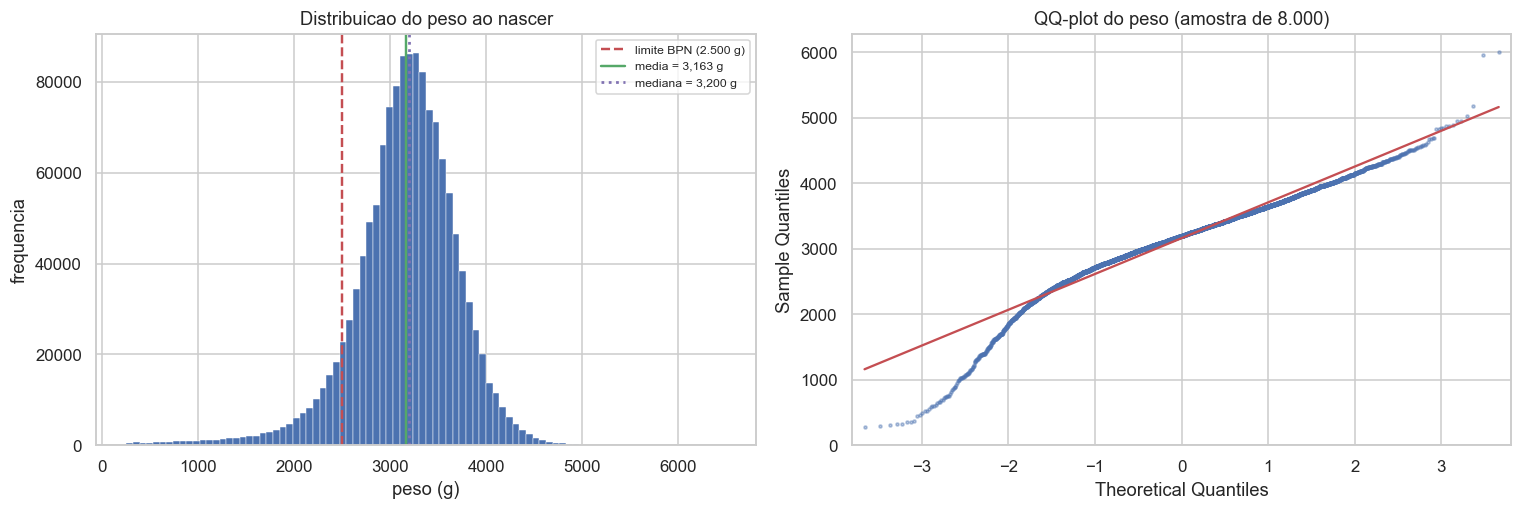

In [12]:
figura, eixos = plt.subplots(1, 2, figsize=(14, 4.8))

eixos[0].hist(peso, bins=90, color="#4C72B0", edgecolor="white", linewidth=0.3)
eixos[0].axvline(2500, color="#C44E52", linestyle="--", linewidth=1.6, label="limite BPN (2.500 g)")
eixos[0].axvline(peso.mean(), color="#55A868", linewidth=1.6, label=f"media = {peso.mean():,.0f} g")
eixos[0].axvline(peso.median(), color="#8172B2", linestyle=":", linewidth=1.8,
                 label=f"mediana = {peso.median():,.0f} g")
eixos[0].set_title("Distribuicao do peso ao nascer")
eixos[0].set_xlabel("peso (g)")
eixos[0].set_ylabel("frequencia")
eixos[0].legend(fontsize=8)

sm.qqplot(peso.sample(8000, random_state=SEED), line="s", ax=eixos[1], markersize=2, alpha=0.4)
eixos[1].set_title("QQ-plot do peso (amostra de 8.000)")

plt.tight_layout()
plt.show()

In [13]:
def intervalo_proporcao(serie, rotulo):
    amostra = serie.dropna()
    sucessos = int(amostra.sum())
    total = len(amostra)
    inferior, superior = proportion_confint(sucessos, total, alpha=ALPHA, method="wilson")
    return {
        "indicador": rotulo,
        "n": total,
        "casos": sucessos,
        "proporcao_%": sucessos / total * 100,
        "ic_inferior_%": inferior * 100,
        "ic_superior_%": superior * 100,
        "amplitude_pp": (superior - inferior) * 100,
    }


prevalencias = pd.DataFrame([
    intervalo_proporcao(completo["BAIXO_PESO"], "Baixo peso (< 2.500 g)"),
    intervalo_proporcao(completo["MUITO_BAIXO_PESO"], "Muito baixo peso (< 1.500 g)"),
    intervalo_proporcao(completo["PREMATURO"], "Prematuridade (< 37 sem)"),
    intervalo_proporcao(completo["CESAREA"], "Parto cesareo"),
    intervalo_proporcao(completo["PRENATAL_ADEQ"], "Pre-natal adequado (Kotelchuck 4-5)"),
    intervalo_proporcao(completo["MULTIPLA"], "Gestacao multipla"),
    intervalo_proporcao(completo["SEM_COMPANHEIRO"], "Mae sem companheiro"),
]).set_index("indicador")

prevalencias.round(3)

,n,casos,proporcao_%,ic_inferior_%,ic_superior_%,amplitude_pp
indicador,,,,,,
Baixo peso (< 2.500 g),1388675,125569,9.042,8.995,9.090,0.095
Muito baixo peso (< 1.500 g),1388675,18279,1.316,1.297,1.335,0.038
Prematuridade (< 37 sem),1388675,170178,12.255,12.200,12.309,0.109
Parto cesareo,1388675,868608,62.549,62.469,62.630,0.161
Pre-natal adequado (Kotelchuck 4-5),1388675,1124593,80.983,80.918,81.048,0.131
Gestacao multipla,1388675,32344,2.329,2.304,2.354,0.050
Mae sem companheiro,1388675,776305,55.903,55.820,55.985,0.165


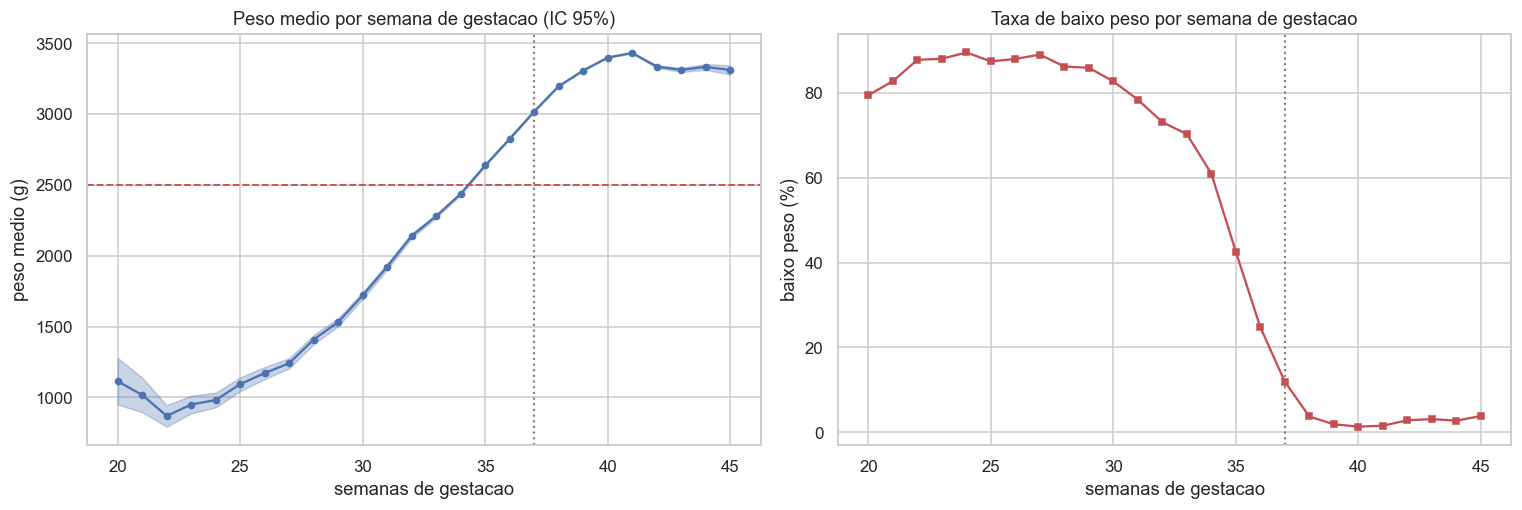

,n,media,desvio,taxa_bpn,erro_padrao,ic_inf,ic_sup
SEMAGESTAC,,,,,,,
28.000,2231,"1,408.530",781.900,86.240,16.550,"1,376.090","1,440.980"
32.000,8261,"2,141.010",713.030,73.140,7.840,"2,125.630","2,156.380"
34.000,22885,"2,437.230",584.470,61.010,3.860,"2,429.660","2,444.800"
36.000,71118,"2,825.580",496.350,24.780,1.860,"2,821.930","2,829.230"
37.000,188206,"3,018.340",462.120,11.930,1.070,"3,016.250","3,020.430"
38.000,333551,"3,196.960",419.540,3.720,0.730,"3,195.540","3,198.390"
39.000,392057,"3,307.320",410.260,1.890,0.660,"3,306.040","3,308.610"
40.000,222569,"3,399.320",421.570,1.320,0.890,"3,397.570","3,401.070"
41.000,62841,"3,431.580",440.070,1.550,1.760,"3,428.140","3,435.020"


In [14]:
por_semana = (
    completo.groupby("SEMAGESTAC")
    .agg(n=("PESO", "size"), media=("PESO", "mean"), desvio=("PESO", "std"),
         taxa_bpn=("BAIXO_PESO", "mean"))
    .query("n >= 30")
)
por_semana["erro_padrao"] = por_semana["desvio"] / np.sqrt(por_semana["n"])
por_semana["ic_inf"] = por_semana["media"] - st.norm.ppf(0.975) * por_semana["erro_padrao"]
por_semana["ic_sup"] = por_semana["media"] + st.norm.ppf(0.975) * por_semana["erro_padrao"]
por_semana["taxa_bpn"] *= 100

figura, eixos = plt.subplots(1, 2, figsize=(14, 4.8))

eixos[0].plot(por_semana.index, por_semana["media"], marker="o", markersize=4, color="#4C72B0")
eixos[0].fill_between(por_semana.index, por_semana["ic_inf"], por_semana["ic_sup"],
                      alpha=0.3, color="#4C72B0")
eixos[0].axhline(2500, color="#C44E52", linestyle="--", linewidth=1.2)
eixos[0].axvline(37, color="#937860", linestyle=":", linewidth=1.4)
eixos[0].set_title("Peso medio por semana de gestacao (IC 95%)")
eixos[0].set_xlabel("semanas de gestacao")
eixos[0].set_ylabel("peso medio (g)")

eixos[1].plot(por_semana.index, por_semana["taxa_bpn"], marker="s", markersize=4, color="#C44E52")
eixos[1].axvline(37, color="#937860", linestyle=":", linewidth=1.4)
eixos[1].set_title("Taxa de baixo peso por semana de gestacao")
eixos[1].set_xlabel("semanas de gestacao")
eixos[1].set_ylabel("baixo peso (%)")

plt.tight_layout()
plt.show()

por_semana.loc[[28, 32, 34, 36, 37, 38, 39, 40, 41]].round(2)

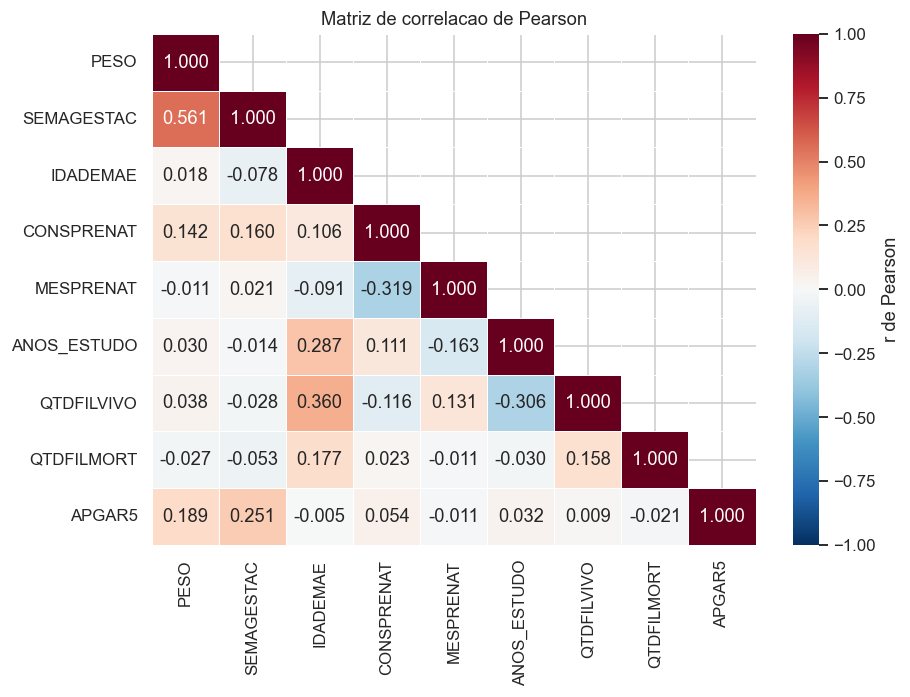

,r com PESO
SEMAGESTAC,0.561
APGAR5,0.189
CONSPRENAT,0.142
QTDFILVIVO,0.038
ANOS_ESTUDO,0.030
QTDFILMORT,-0.027
IDADEMAE,0.018
MESPRENAT,-0.011


In [15]:
CONTINUAS = ["PESO", "SEMAGESTAC", "IDADEMAE", "CONSPRENAT", "MESPRENAT",
             "ANOS_ESTUDO", "QTDFILVIVO", "QTDFILMORT", "APGAR5"]

matriz_correlacao = dados[CONTINUAS].corr(method="pearson")

figura, eixo = plt.subplots(figsize=(8.5, 6.5))
mascara = np.triu(np.ones_like(matriz_correlacao, dtype=bool), k=1)
sns.heatmap(matriz_correlacao, mask=mascara, annot=True, fmt=".3f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "r de Pearson"},
            ax=eixo)
eixo.set_title("Matriz de correlacao de Pearson")
plt.tight_layout()
plt.show()

matriz_correlacao["PESO"].drop("PESO").sort_values(key=abs, ascending=False).round(4).to_frame("r com PESO")

In [16]:
def resumo_por_grupo(frame, coluna):
    tabela = (
        frame.groupby(coluna, observed=True)
        .agg(n=("PESO", "size"), peso_medio=("PESO", "mean"), desvio=("PESO", "std"),
             taxa_bpn=("BAIXO_PESO", "mean"), taxa_prematuro=("PREMATURO", "mean"),
             taxa_cesarea=("CESAREA", "mean"), prenatal_adequado=("PRENATAL_ADEQ", "mean"))
    )
    tabela["erro_padrao"] = tabela["desvio"] / np.sqrt(tabela["n"])
    tabela["ic_inf"] = tabela["peso_medio"] - st.norm.ppf(0.975) * tabela["erro_padrao"]
    tabela["ic_sup"] = tabela["peso_medio"] + st.norm.ppf(0.975) * tabela["erro_padrao"]
    for coluna_taxa in ["taxa_bpn", "taxa_prematuro", "taxa_cesarea", "prenatal_adequado"]:
        tabela[coluna_taxa] *= 100
    return tabela.round(2)


resumo_escolaridade = resumo_por_grupo(completo, "ESC_CAT")
resumo_escolaridade

,n,peso_medio,desvio,taxa_bpn,taxa_prematuro,taxa_cesarea,prenatal_adequado,erro_padrao,ic_inf,ic_sup
ESC_CAT,,,,,,,,,,
0 Sem escolaridade,2552,"3,036.560",580.400,14.180,15.990,36.250,43.810,11.490,"3,014.040","3,059.080"
1 Fundamental I,20823,"3,128.410",585.460,11.440,16.620,50.130,66.920,4.060,"3,120.460","3,136.370"
2 Fundamental II,204016,"3,131.640",560.090,10.350,14.120,51.970,70.240,1.240,"3,129.210","3,134.070"
3 Medio,792492,"3,166.760",550.300,8.920,11.950,60.280,80.830,0.620,"3,165.550","3,167.970"
4 Superior incompleto,75762,"3,179.270",541.850,8.530,11.640,69.730,83.860,1.970,"3,175.410","3,183.130"
5 Superior completo,293030,"3,174.590",529.730,8.390,11.610,75.310,89.450,0.980,"3,172.680","3,176.510"


In [17]:
resumo_faixa_idade = resumo_por_grupo(completo, "FAIXA_MAE")
resumo_prenatal = resumo_por_grupo(completo, "PRENATAL_ADEQ")
resumo_regiao = resumo_por_grupo(completo, "REGIAO")

display(resumo_faixa_idade)
display(resumo_prenatal)
display(resumo_regiao)

,n,peso_medio,desvio,taxa_bpn,taxa_prematuro,taxa_cesarea,prenatal_adequado,erro_padrao,ic_inf,ic_sup
FAIXA_MAE,,,,,,,,,,
Adolescente,149941,"3,088.270",537.150,10.440,13.420,47.740,70.440,1.390,"3,085.550","3,090.990"
20-34,984683,"3,178.700",542.050,8.460,11.390,62.100,81.720,0.550,"3,177.630","3,179.770"
35 ou mais,254051,"3,146.910",571.840,10.480,14.900,73.050,84.360,1.130,"3,144.690","3,149.140"


,n,peso_medio,desvio,taxa_bpn,taxa_prematuro,taxa_cesarea,prenatal_adequado,erro_padrao,ic_inf,ic_sup
PRENATAL_ADEQ,,,,,,,,,,
0.000,264082,"3,060.340",652.070,13.800,17.940,52.970,0.000,1.270,"3,057.850","3,062.830"
1.000,1124593,"3,187.260",517.410,7.930,10.920,64.800,100.000,0.490,"3,186.300","3,188.220"


,n,peso_medio,desvio,taxa_bpn,taxa_prematuro,taxa_cesarea,prenatal_adequado,erro_padrao,ic_inf,ic_sup
REGIAO,,,,,,,,,,
CO,129082,"3,139.330",537.250,9.240,12.530,67.920,80.500,1.500,"3,136.400","3,142.260"
N,149371,"3,197.450",546.390,7.970,12.890,57.660,68.780,1.410,"3,194.680","3,200.220"
NE,355356,"3,185.420",556.390,8.630,12.800,62.130,79.250,0.930,"3,183.590","3,187.250"
S,217581,"3,172.620",544.370,8.950,11.740,63.550,85.300,1.170,"3,170.330","3,174.910"
SE,537285,"3,140.700",545.270,9.600,11.860,62.490,83.890,0.740,"3,139.240","3,142.160"


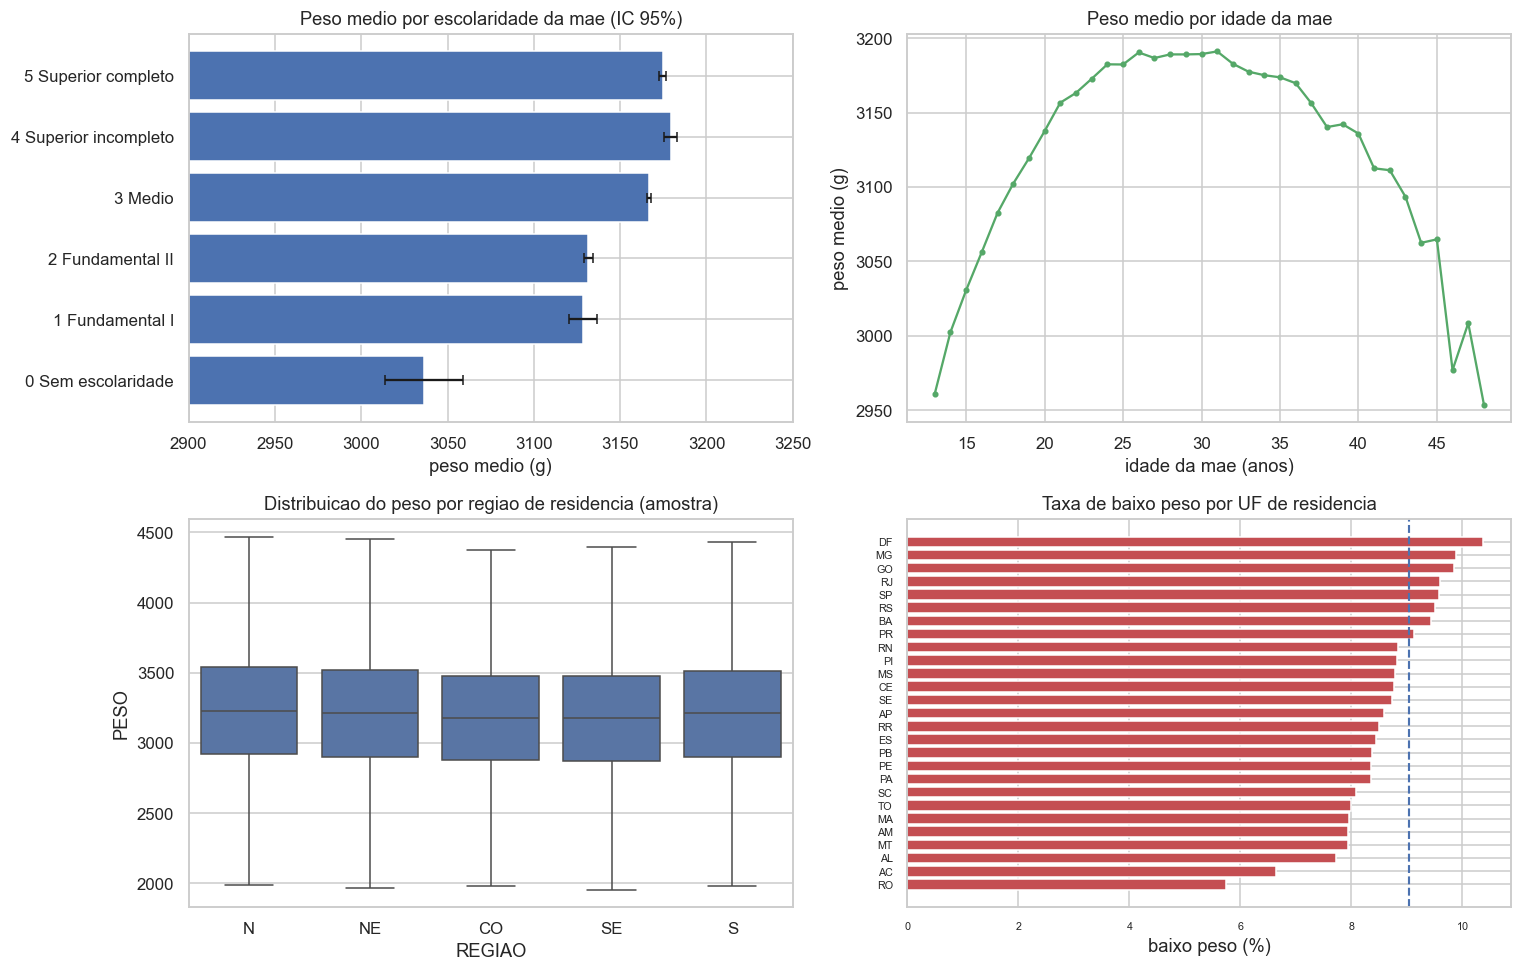

In [18]:
figura, eixos = plt.subplots(2, 2, figsize=(14, 9))

ordem_escolaridade = resumo_escolaridade.index.tolist()
eixos[0, 0].barh(ordem_escolaridade, resumo_escolaridade["peso_medio"],
                 xerr=(resumo_escolaridade["peso_medio"] - resumo_escolaridade["ic_inf"]),
                 color="#4C72B0", capsize=3)
eixos[0, 0].set_xlim(2900, 3250)
eixos[0, 0].set_title("Peso medio por escolaridade da mae (IC 95%)")
eixos[0, 0].set_xlabel("peso medio (g)")

por_idade = (
    completo.groupby(completo["IDADEMAE"].round())
    .agg(n=("PESO", "size"), media=("PESO", "mean"))
    .query("n >= 200")
)
eixos[0, 1].plot(por_idade.index, por_idade["media"], marker="o", markersize=3, color="#55A868")
eixos[0, 1].set_title("Peso medio por idade da mae")
eixos[0, 1].set_xlabel("idade da mae (anos)")
eixos[0, 1].set_ylabel("peso medio (g)")

sns.boxplot(data=completo.sample(120000, random_state=SEED), x="REGIAO", y="PESO",
            order=["N", "NE", "CO", "SE", "S"], showfliers=False, ax=eixos[1, 0])
eixos[1, 0].set_title("Distribuicao do peso por regiao de residencia (amostra)")

taxa_uf = (completo.groupby("UF")["BAIXO_PESO"].mean().mul(100).sort_values())
eixos[1, 1].barh(taxa_uf.index, taxa_uf.values, color="#C44E52")
eixos[1, 1].axvline(completo["BAIXO_PESO"].mean() * 100, color="#4C72B0",
                    linestyle="--", linewidth=1.4)
eixos[1, 1].set_title("Taxa de baixo peso por UF de residencia")
eixos[1, 1].set_xlabel("baixo peso (%)")
eixos[1, 1].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

In [19]:
serie_mensal = (
    completo.dropna(subset=["DATA_NASC"])
    .groupby(completo["DATA_NASC"].dt.to_period("M"))
    .agg(nascimentos=("PESO", "size"), peso_medio=("PESO", "mean"),
         taxa_bpn=("BAIXO_PESO", "mean"), taxa_cesarea=("CESAREA", "mean"),
         taxa_prematuro=("PREMATURO", "mean"), prenatal_adequado=("PRENATAL_ADEQ", "mean"))
)
for coluna_taxa in ["taxa_bpn", "taxa_cesarea", "taxa_prematuro", "prenatal_adequado"]:
    serie_mensal[coluna_taxa] *= 100

display(serie_mensal.round(3))

indice = np.arange(len(serie_mensal))
tendencia_peso = st.linregress(indice, serie_mensal["peso_medio"])
tendencia_bpn = st.linregress(indice, serie_mensal["taxa_bpn"])

print(f"tendencia do peso medio: {tendencia_peso.slope:+.2f} g/mes | "
      f"p = {tendencia_peso.pvalue:.3f} | R2 = {tendencia_peso.rvalue ** 2:.3f}")
print(f"tendencia da taxa de BPN: {tendencia_bpn.slope:+.4f} pp/mes | "
      f"p = {tendencia_bpn.pvalue:.3f} | R2 = {tendencia_bpn.rvalue ** 2:.3f}")

,nascimentos,peso_medio,taxa_bpn,taxa_cesarea,taxa_prematuro,prenatal_adequado
DATA_NASC,,,,,,
2026-01,185019,"3,168.926",9.112,62.415,13.329,79.431
2026-02,169153,"3,163.183",9.133,62.435,13.602,80.248
2026-03,199651,"3,161.316",9.072,62.457,11.963,81.332
2026-04,193774,"3,162.743",9.033,62.304,12.068,81.533
2026-05,194420,"3,159.228",9.023,62.126,11.658,81.603
2026-06,183413,"3,161.417",9.028,62.702,11.987,81.415
2026-07,176188,"3,162.616",9.041,63.222,11.670,80.824
2026-08,87057,"3,168.976",8.746,63.079,11.515,81.715


tendencia do peso medio: -0.07 g/mes | p = 0.912 | R2 = 0.002
tendencia da taxa de BPN: -0.0377 pp/mes | p = 0.024 | R2 = 0.598


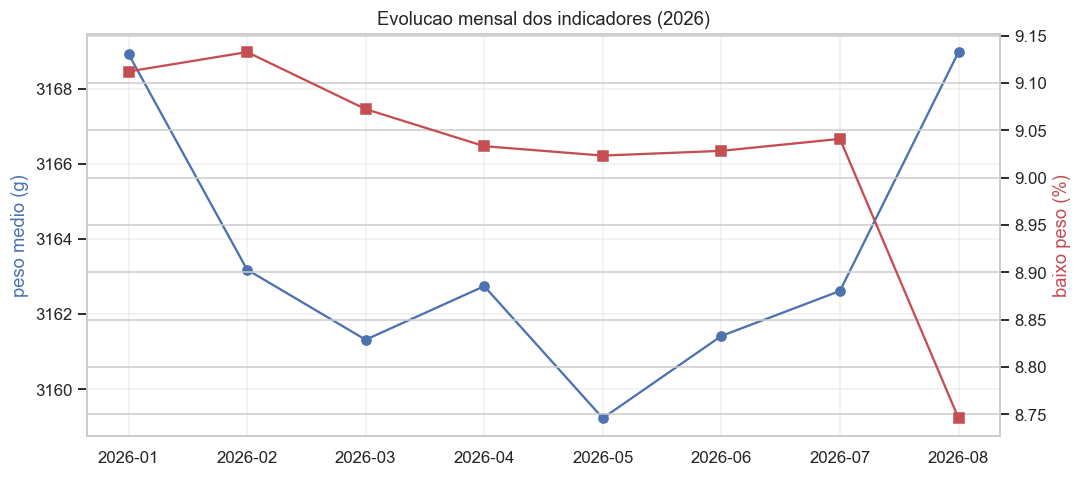

In [20]:
figura, eixo_esquerdo = plt.subplots(figsize=(10, 4.5))
eixo_direito = eixo_esquerdo.twinx()

rotulos = serie_mensal.index.astype(str)
eixo_esquerdo.plot(rotulos, serie_mensal["peso_medio"], marker="o", color="#4C72B0",
                   label="peso medio (g)")
eixo_direito.plot(rotulos, serie_mensal["taxa_bpn"], marker="s", color="#C44E52",
                  label="taxa de BPN (%)")

eixo_esquerdo.set_ylabel("peso medio (g)", color="#4C72B0")
eixo_direito.set_ylabel("baixo peso (%)", color="#C44E52")
eixo_esquerdo.set_title("Evolucao mensal dos indicadores (2026)")
eixo_esquerdo.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
def ic_media(serie, confianca=1 - ALPHA):
    amostra = serie.dropna()
    n = len(amostra)
    media = amostra.mean()
    desvio = amostra.std(ddof=1)
    erro_padrao = desvio / np.sqrt(n)
    graus_liberdade = n - 1
    inferior, superior = st.t.interval(confianca, graus_liberdade, loc=media, scale=erro_padrao)
    return pd.Series({
        "n": n,
        "media": media,
        "desvio_padrao": desvio,
        "erro_padrao": erro_padrao,
        "graus_liberdade": graus_liberdade,
        "t_critico": st.t.ppf(1 - (1 - confianca) / 2, graus_liberdade),
        "ic_inferior": inferior,
        "ic_superior": superior,
        "amplitude": superior - inferior,
    })


ic_peso_geral = ic_media(completo["PESO"])
display(ic_peso_geral.round(4).to_frame("PESO (g)"))

ic_por_regiao = (
    completo.groupby("REGIAO")["PESO"]
    .apply(ic_media)
    .unstack()
    .loc[:, ["n", "media", "erro_padrao", "graus_liberdade", "ic_inferior", "ic_superior", "amplitude"]]
)
ic_por_regiao.round(2)

,PESO (g)
n,"1,388,675.000"
media,"3,163.123"
desvio_padrao,547.852
erro_padrao,0.465
graus_liberdade,"1,388,674.000"
t_critico,1.960
ic_inferior,"3,162.211"
ic_superior,"3,164.034"
amplitude,1.822


,n,media,erro_padrao,graus_liberdade,ic_inferior,ic_superior,amplitude
REGIAO,,,,,,,
CO,"129,082.000","3,139.330",1.500,"129,081.000","3,136.400","3,142.260",5.860
N,"149,371.000","3,197.450",1.410,"149,370.000","3,194.680","3,200.220",5.540
NE,"355,356.000","3,185.420",0.930,"355,355.000","3,183.590","3,187.250",3.660
S,"217,581.000","3,172.620",1.170,"217,580.000","3,170.330","3,174.910",4.570
SE,"537,285.000","3,140.700",0.740,"537,284.000","3,139.240","3,142.160",2.920


In [22]:
def teste_welch(grupo_a, grupo_b, nome_a, nome_b, confianca=1 - ALPHA):
    a = grupo_a.dropna()
    b = grupo_b.dropna()
    n_a, n_b = len(a), len(b)
    var_a, var_b = a.var(ddof=1), b.var(ddof=1)
    estatistica, valor_p = st.ttest_ind(a, b, equal_var=False)
    diferenca = a.mean() - b.mean()
    erro_padrao = np.sqrt(var_a / n_a + var_b / n_b)
    graus_liberdade = (var_a / n_a + var_b / n_b) ** 2 / (
        (var_a / n_a) ** 2 / (n_a - 1) + (var_b / n_b) ** 2 / (n_b - 1)
    )
    t_critico = st.t.ppf(1 - (1 - confianca) / 2, graus_liberdade)
    d = diferenca / np.sqrt(((n_a - 1) * var_a + (n_b - 1) * var_b) / (n_a + n_b - 2))
    return pd.Series({
        f"n_{nome_a}": n_a,
        f"n_{nome_b}": n_b,
        f"media_{nome_a}": a.mean(),
        f"media_{nome_b}": b.mean(),
        f"desvio_{nome_a}": np.sqrt(var_a),
        f"desvio_{nome_b}": np.sqrt(var_b),
        "diferenca": diferenca,
        "erro_padrao_dif": erro_padrao,
        "graus_liberdade_welch": graus_liberdade,
        "t_observado": estatistica,
        "t_critico": t_critico,
        "valor_p": valor_p,
        "ic_inferior": diferenca - t_critico * erro_padrao,
        "ic_superior": diferenca + t_critico * erro_padrao,
        "d_de_cohen": d,
        "rejeita_H0": bool(valor_p < ALPHA),
    })


h1 = teste_welch(
    completo.loc[completo["PRENATAL_ADEQ"] == 1, "PESO"],
    completo.loc[completo["PRENATAL_ADEQ"] == 0, "PESO"],
    "adequado", "inadequado",
)
h1.round(5).to_frame("H1: pre-natal adequado vs inadequado")

,H1: pre-natal adequado vs inadequado
n_adequado,1124593
n_inadequado,264082
media_adequado,"3,187.259"
media_inadequado,"3,060.338"
desvio_adequado,517.411
desvio_inadequado,652.069
diferenca,126.921
erro_padrao_dif,1.359
graus_liberdade_welch,"346,166.910"
t_observado,93.361


In [23]:
h2 = teste_welch(
    completo.loc[completo["CESAREA"] == 1, "PESO"],
    completo.loc[completo["CESAREA"] == 0, "PESO"],
    "cesareo", "vaginal",
)
display(h2.round(5).to_frame("H2: cesareo vs vaginal"))

h2_adolescente = teste_welch(
    completo.loc[completo["FAIXA_MAE"] == "Adolescente", "PESO"],
    completo.loc[completo["FAIXA_MAE"] == "20-34", "PESO"],
    "adolescente", "20a34",
)
h2_adolescente.round(5).to_frame("H2b: mae adolescente vs 20-34 anos")

,H2: cesareo vs vaginal
n_cesareo,868608
n_vaginal,520067
media_cesareo,"3,178.568"
media_vaginal,"3,137.327"
desvio_cesareo,562.965
desvio_vaginal,520.615
diferenca,41.241
erro_padrao_dif,0.941
graus_liberdade_welch,"1,162,130.539"
t_observado,43.813


,H2b: mae adolescente vs 20-34 anos
n_adolescente,149941
n_20a34,984683
media_adolescente,"3,088.268"
media_20a34,"3,178.703"
desvio_adolescente,537.152
desvio_20a34,542.050
diferenca,-90.436
erro_padrao_dif,1.491
graus_liberdade_welch,"199,315.795"
t_observado,-60.660


In [24]:
grupos_escolaridade = [
    grupo["PESO"].dropna().values
    for _, grupo in completo.groupby("ESC_CAT", observed=True)
]
rotulos_escolaridade = sorted(completo["ESC_CAT"].dropna().unique())

f_observado, p_anova = st.f_oneway(*grupos_escolaridade)
k_grupos = len(grupos_escolaridade)
n_total = sum(len(g) for g in grupos_escolaridade)
media_geral = np.concatenate(grupos_escolaridade).mean()

soma_quadrados_entre = sum(len(g) * (g.mean() - media_geral) ** 2 for g in grupos_escolaridade)
soma_quadrados_dentro = sum(((g - g.mean()) ** 2).sum() for g in grupos_escolaridade)
eta_quadrado = soma_quadrados_entre / (soma_quadrados_entre + soma_quadrados_dentro)

levene_estatistica, levene_p = st.levene(*grupos_escolaridade, center="median")
kruskal_estatistica, kruskal_p = st.kruskal(*grupos_escolaridade)

pd.Series({
    "k_grupos": k_grupos,
    "N_total": n_total,
    "gl_entre": k_grupos - 1,
    "gl_dentro": n_total - k_grupos,
    "soma_quadrados_entre": soma_quadrados_entre,
    "soma_quadrados_dentro": soma_quadrados_dentro,
    "quadrado_medio_entre": soma_quadrados_entre / (k_grupos - 1),
    "quadrado_medio_dentro": soma_quadrados_dentro / (n_total - k_grupos),
    "F_observado": f_observado,
    "F_critico": st.f.ppf(1 - ALPHA, k_grupos - 1, n_total - k_grupos),
    "valor_p_anova": p_anova,
    "eta_quadrado": eta_quadrado,
    "levene_estatistica": levene_estatistica,
    "levene_valor_p": levene_p,
    "kruskal_estatistica": kruskal_estatistica,
    "kruskal_valor_p": kruskal_p,
}).round(6).to_frame("H3: ANOVA escolaridade")

,H3: ANOVA escolaridade
k_grupos,6.000
N_total,"1,388,675.000"
gl_entre,5.000
gl_dentro,"1,388,669.000"
soma_quadrados_entre,"336,916,616.051"
soma_quadrados_dentro,"416,462,856,392.502"
quadrado_medio_entre,"67,383,323.210"
quadrado_medio_dentro,"299,900.737"
F_observado,224.685
F_critico,2.214


In [25]:
amostra_tukey = completo[["PESO", "ESC_CAT"]].dropna().sample(60000, random_state=SEED)
resultado_tukey = pairwise_tukeyhsd(amostra_tukey["PESO"], amostra_tukey["ESC_CAT"], alpha=ALPHA)
print(resultado_tukey.summary())

                Multiple Comparison of Means - Tukey HSD, FWER=0.05                 
        group1                group2        meandiff p-adj   lower    upper   reject
------------------------------------------------------------------------------------
   0 Sem escolaridade       1 Fundamental I 121.5961 0.2247 -33.9278   277.12  False
   0 Sem escolaridade      2 Fundamental II 112.7951 0.2469 -34.6292 260.2193  False
   0 Sem escolaridade               3 Medio 154.3178 0.0326   7.5849 301.0507   True
   0 Sem escolaridade 4 Superior incompleto  174.932 0.0106  25.9417 323.9223   True
   0 Sem escolaridade   5 Superior completo 174.4851 0.0095  27.3381 321.6321   True
      1 Fundamental I      2 Fundamental II   -8.801 0.9975 -63.6249  46.0228  False
      1 Fundamental I               3 Medio  32.7217 0.4909  -20.215  85.6584  False
      1 Fundamental I 4 Superior incompleto  53.3359 0.1021  -5.5697 112.2415  False
      1 Fundamental I   5 Superior completo   52.889 0.0595  -1.1

In [26]:
par_gestacao = completo[["SEMAGESTAC", "PESO"]].dropna()
n_par = len(par_gestacao)

r_pearson, p_pearson = st.pearsonr(par_gestacao["SEMAGESTAC"], par_gestacao["PESO"])
r_spearman, p_spearman = st.spearmanr(par_gestacao["SEMAGESTAC"], par_gestacao["PESO"])

z_fisher = np.arctanh(r_pearson)
erro_padrao_z = 1 / np.sqrt(n_par - 3)
z_critico = st.norm.ppf(1 - ALPHA / 2)
ic_r = (np.tanh(z_fisher - z_critico * erro_padrao_z),
        np.tanh(z_fisher + z_critico * erro_padrao_z))
t_correlacao = r_pearson * np.sqrt((n_par - 2) / (1 - r_pearson ** 2))

correlacoes_peso = {}
for preditora in ["CONSPRENAT", "ANOS_ESTUDO", "IDADEMAE", "MESPRENAT", "QTDFILVIVO"]:
    par = completo[[preditora, "PESO"]].dropna()
    r_valor, p_valor = st.pearsonr(par[preditora], par["PESO"])
    z_valor = np.arctanh(r_valor)
    ep_valor = 1 / np.sqrt(len(par) - 3)
    correlacoes_peso[preditora] = {
        "n": len(par),
        "r": r_valor,
        "valor_p": p_valor,
        "ic_inferior": np.tanh(z_valor - z_critico * ep_valor),
        "ic_superior": np.tanh(z_valor + z_critico * ep_valor),
        "r2_%": r_valor ** 2 * 100,
    }

display(pd.Series({
    "n": n_par,
    "graus_liberdade": n_par - 2,
    "r_pearson": r_pearson,
    "t_observado": t_correlacao,
    "valor_p": p_pearson,
    "ic_inferior": ic_r[0],
    "ic_superior": ic_r[1],
    "r2_%": r_pearson ** 2 * 100,
    "r_spearman": r_spearman,
    "valor_p_spearman": p_spearman,
}).round(6).to_frame("H4: correlacao SEMAGESTAC x PESO"))

pd.DataFrame(correlacoes_peso).T.round(5)

,H4: correlacao SEMAGESTAC x PESO
n,"1,388,675.000"
graus_liberdade,"1,388,673.000"
r_pearson,0.557
t_observado,789.897
valor_p,0.000
ic_inferior,0.556
ic_superior,0.558
r2_%,31.001
r_spearman,0.416
valor_p_spearman,0.000


,n,r,valor_p,ic_inferior,ic_superior,r2_%
CONSPRENAT,"1,388,675.000",0.134,0.000,0.133,0.136,1.809
ANOS_ESTUDO,"1,388,675.000",0.024,0.000,0.023,0.026,0.059
IDADEMAE,"1,388,675.000",0.017,0.000,0.015,0.019,0.029
MESPRENAT,"1,388,675.000",-0.012,0.000,-0.014,-0.010,0.014
QTDFILVIVO,"1,388,675.000",0.044,0.000,0.042,0.046,0.194


In [27]:
tabela_contingencia = pd.crosstab(completo["PRENATAL_ADEQ"], completo["BAIXO_PESO"])
tabela_contingencia.index = ["Pre-natal inadequado", "Pre-natal adequado"]
tabela_contingencia.columns = ["Peso >= 2500 g", "Baixo peso"]
display(tabela_contingencia)

chi2_observado, p_chi2, gl_chi2, esperadas = st.chi2_contingency(tabela_contingencia)
display(pd.DataFrame(esperadas, index=tabela_contingencia.index,
                     columns=tabela_contingencia.columns).round(1))

n_inadequado = tabela_contingencia.loc["Pre-natal inadequado"].sum()
n_adequado = tabela_contingencia.loc["Pre-natal adequado"].sum()
casos_inadequado = tabela_contingencia.loc["Pre-natal inadequado", "Baixo peso"]
casos_adequado = tabela_contingencia.loc["Pre-natal adequado", "Baixo peso"]

p_inadequado = casos_inadequado / n_inadequado
p_adequado = casos_adequado / n_adequado
diferenca_risco = p_inadequado - p_adequado
erro_padrao_risco = np.sqrt(
    p_inadequado * (1 - p_inadequado) / n_inadequado + p_adequado * (1 - p_adequado) / n_adequado
)
z_proporcoes, p_proporcoes = proportions_ztest(
    [casos_inadequado, casos_adequado], [n_inadequado, n_adequado]
)
risco_relativo = p_inadequado / p_adequado
erro_padrao_log_rr = np.sqrt(
    (1 - p_inadequado) / casos_inadequado + (1 - p_adequado) / casos_adequado
)
v_cramer = np.sqrt(
    chi2_observado / tabela_contingencia.values.sum() / (min(tabela_contingencia.shape) - 1)
)

pd.Series({
    "chi2_observado": chi2_observado,
    "graus_liberdade": gl_chi2,
    "chi2_critico": st.chi2.ppf(1 - ALPHA, gl_chi2),
    "valor_p_chi2": p_chi2,
    "menor_frequencia_esperada": esperadas.min(),
    "risco_inadequado_%": p_inadequado * 100,
    "risco_adequado_%": p_adequado * 100,
    "diferenca_risco_pp": diferenca_risco * 100,
    "ic_inferior_pp": (diferenca_risco - z_critico * erro_padrao_risco) * 100,
    "ic_superior_pp": (diferenca_risco + z_critico * erro_padrao_risco) * 100,
    "z_proporcoes": z_proporcoes,
    "valor_p_z": p_proporcoes,
    "risco_relativo": risco_relativo,
    "rr_ic_inferior": np.exp(np.log(risco_relativo) - z_critico * erro_padrao_log_rr),
    "rr_ic_superior": np.exp(np.log(risco_relativo) + z_critico * erro_padrao_log_rr),
    "v_de_cramer": v_cramer,
    "casos_atribuiveis_estimados": diferenca_risco * n_inadequado,
}).round(5).to_frame("H5: pre-natal x baixo peso")

,Peso >= 2500 g,Baixo peso
Pre-natal inadequado,227641,36441
Pre-natal adequado,1035465,89128


,Peso >= 2500 g,Baixo peso
Pre-natal inadequado,"240,202.800","23,879.200"
Pre-natal adequado,"1,022,903.200","101,689.800"


,H5: pre-natal x baixo peso
chi2_observado,"8,970.392"
graus_liberdade,1.000
chi2_critico,3.841
valor_p_chi2,0.000
menor_frequencia_esperada,"23,879.247"
risco_inadequado_%,13.799
risco_adequado_%,7.925
diferenca_risco_pp,5.874
ic_inferior_pp,5.733
ic_superior_pp,6.014


In [28]:
modelagem = completo[VARIAVEIS_MODELO + ["SEMAGESTAC_C", "SEMAGESTAC_C2", "IDADEMAE_C",
                                         "PREMATURO", "UF", "BAIXO_PESO"]].dropna().copy()

treino, teste = train_test_split(modelagem, test_size=0.2, random_state=SEED)

print(f"amostra de modelagem..: {len(modelagem):,}")
print(f"treino (80%)..........: {len(treino):,}")
print(f"teste  (20%)..........: {len(teste):,}")
print()
print("verificacao de equivalencia entre as particoes")
comparacao_particoes = pd.DataFrame({
    "treino": treino[["PESO", "SEMAGESTAC", "IDADEMAE", "CONSPRENAT", "PRENATAL_ADEQ", "CESAREA"]].mean(),
    "teste": teste[["PESO", "SEMAGESTAC", "IDADEMAE", "CONSPRENAT", "PRENATAL_ADEQ", "CESAREA"]].mean(),
})
comparacao_particoes["diferenca_%"] = (
    (comparacao_particoes["teste"] / comparacao_particoes["treino"] - 1) * 100
)
comparacao_particoes.round(4)

amostra de modelagem..: 1,388,675
treino (80%)..........: 1,110,940
teste  (20%)..........: 277,735

verificacao de equivalencia entre as particoes


,treino,teste,diferenca_%
PESO,"3,163.378","3,162.100",-0.040
SEMAGESTAC,38.194,38.189,-0.014
IDADEMAE,27.923,27.927,0.013
CONSPRENAT,9.274,9.280,0.067
PRENATAL_ADEQ,0.810,0.811,0.148
CESAREA,0.625,0.626,0.059


In [29]:
m1 = smf.ols("PESO ~ SEMAGESTAC_C", data=treino).fit()
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:                   PESO   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.308
Method:                 Least Squares   F-statistic:                 4.947e+05
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:12:35   Log-Likelihood:            -8.3763e+06
No. Observations:             1110940   AIC:                         1.675e+07
Df Residuals:                 1110938   BIC:                         1.675e+07
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     3279.4828      0.462   7091.999   

In [30]:
resumo_m1 = pd.DataFrame({
    "coeficiente": m1.params,
    "erro_padrao": m1.bse,
    "t": m1.tvalues,
    "valor_p": m1.pvalues,
    "ic_inferior": m1.conf_int()[0],
    "ic_superior": m1.conf_int()[1],
})
display(resumo_m1.round(4))

print(f"R2................: {m1.rsquared:.4f}")
print(f"R2 ajustado.......: {m1.rsquared_adj:.4f}")
print(f"erro padrao resid.: {np.sqrt(m1.mse_resid):,.1f} g")
print(f"gl do modelo......: {int(m1.df_model)}")
print(f"gl dos residuos...: {int(m1.df_resid):,}")
print(f"F.................: {m1.fvalue:,.1f} (p = {m1.f_pvalue:.3g})")

,coeficiente,erro_padrao,t,valor_p,ic_inferior,ic_superior
Intercept,"3,279.483",0.462,"7,091.999",0.000,"3,278.577","3,280.389"
SEMAGESTAC_C,144.070,0.205,703.341,0.000,143.669,144.472


R2................: 0.3081
R2 ajustado.......: 0.3081
erro padrao resid.: 455.3 g
gl do modelo......: 1
gl dos residuos...: 1,110,938
F.................: 494,689.1 (p = 0)


In [31]:
m2 = smf.ols("PESO ~ SEMAGESTAC_C + SEMAGESTAC_C2", data=treino).fit()

resumo_m2 = pd.DataFrame({
    "coeficiente": m2.params,
    "erro_padrao": m2.bse,
    "t": m2.tvalues,
    "valor_p": m2.pvalues,
    "ic_inferior": m2.conf_int()[0],
    "ic_superior": m2.conf_int()[1],
})
display(resumo_m2.round(4))

teste_quadratico = m2.compare_f_test(m1)
print(f"R2 de M1..........: {m1.rsquared:.4f}")
print(f"R2 de M2..........: {m2.rsquared:.4f}")
print(f"teste F de M1 vs M2: F = {teste_quadratico[0]:,.1f} | p = {teste_quadratico[1]:.3g} | "
      f"gl = {teste_quadratico[2]:.0f}")

derivada_semanas = np.array([28, 32, 36, 39, 41])
ganho_marginal = m2.params["SEMAGESTAC_C"] + 2 * m2.params["SEMAGESTAC_C2"] * (derivada_semanas - 39)
pd.DataFrame({"semana": derivada_semanas, "ganho_marginal_g_por_semana": ganho_marginal}).round(2)

,coeficiente,erro_padrao,t,valor_p,ic_inferior,ic_superior
Intercept,"3,279.188",0.460,"7,126.047",0.000,"3,278.286","3,280.090"
SEMAGESTAC_C,120.915,0.301,401.781,0.000,120.325,121.505
SEMAGESTAC_C2,-3.604,0.035,-104.582,0.000,-3.671,-3.536


R2 de M1..........: 0.3081
R2 de M2..........: 0.3148
teste F de M1 vs M2: F = 10,937.5 | p = 0 | gl = 1


,semana,ganho_marginal_g_por_semana
0,28,200.200
1,32,171.370
2,36,142.540
3,39,120.920
4,41,106.500


In [32]:
FORMULA_M3 = (
    "PESO ~ SEMAGESTAC_C + SEMAGESTAC_C2 + IDADEMAE_C + CONSPRENAT + MESPRENAT "
    "+ ANOS_ESTUDO + QTDFILVIVO + SEXO_M + CESAREA + MULTIPLA + ANOMALIA "
    "+ SEM_COMPANHEIRO + C(REGIAO, Treatment('SE')) + C(RACA_MAE, Treatment('Branca'))"
)

m3 = smf.ols(FORMULA_M3, data=treino).fit()
print(m3.summary())

                            OLS Regression Results                            
Dep. Variable:                   PESO   R-squared:                       0.358
Model:                            OLS   Adj. R-squared:                  0.358
Method:                 Least Squares   F-statistic:                 3.099e+04
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:12:45   Log-Likelihood:            -8.3347e+06
No. Observations:             1110940   AIC:                         1.667e+07
Df Residuals:                 1110919   BIC:                         1.667e+07
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

In [33]:
resumo_m3 = pd.DataFrame({
    "coeficiente": m3.params,
    "erro_padrao": m3.bse,
    "t": m3.tvalues,
    "valor_p": m3.pvalues,
    "ic_inferior": m3.conf_int()[0],
    "ic_superior": m3.conf_int()[1],
    "significativo": m3.pvalues < ALPHA,
})
resumo_m3.sort_values("coeficiente", key=abs, ascending=False).round(4)

,coeficiente,erro_padrao,t,valor_p,ic_inferior,ic_superior,significativo
Intercept,"2,998.111",2.966,"1,010.758",0.000,"2,992.298","3,003.925",True
MULTIPLA,-503.515,2.852,-176.544,0.000,-509.105,-497.925,True
ANOMALIA,-138.488,3.669,-37.745,0.000,-145.679,-131.297,True
SEXO_M,117.607,0.833,141.244,0.000,115.975,119.239,True
SEMAGESTAC_C,115.375,0.300,384.259,0.000,114.787,115.964,True
CESAREA,68.654,0.892,76.950,0.000,66.906,70.403,True
"C(REGIAO, Treatment('SE'))[T.N]",52.400,1.519,34.504,0.000,49.423,55.376,True
"C(REGIAO, Treatment('SE'))[T.NE]",47.047,1.108,42.452,0.000,44.875,49.219,True
QTDFILVIVO,36.902,0.436,84.625,0.000,36.047,37.757,True
"C(RACA_MAE, Treatment('Branca'))[T.Preta]",-27.048,1.652,-16.377,0.000,-30.286,-23.811,True


In [34]:
m4 = smf.ols(FORMULA_M3 + " + PRENATAL_ADEQ", data=treino).fit()

comparacao_colinearidade = pd.DataFrame({
    "M3_sem_kotelchuck": m3.params.reindex(["CONSPRENAT", "MESPRENAT"]),
    "M4_com_kotelchuck": m4.params.reindex(["CONSPRENAT", "MESPRENAT", "PRENATAL_ADEQ"]),
})
display(comparacao_colinearidade.round(4))

PREDITORAS_VIF = ["SEMAGESTAC_C", "IDADEMAE_C", "CONSPRENAT", "MESPRENAT", "ANOS_ESTUDO",
                  "QTDFILVIVO", "SEXO_M", "CESAREA", "MULTIPLA", "ANOMALIA", "SEM_COMPANHEIRO"]

def calcular_vif(frame, colunas):
    matriz = sm.add_constant(frame[colunas].astype(float))
    return pd.Series(
        [variance_inflation_factor(matriz.values, i) for i in range(matriz.shape[1])],
        index=matriz.columns, name="VIF",
    )

vif_m3 = calcular_vif(treino, PREDITORAS_VIF)
vif_m4 = calcular_vif(treino, PREDITORAS_VIF + ["PRENATAL_ADEQ"])

display(pd.concat([vif_m3.rename("VIF_M3"), vif_m4.rename("VIF_M4")], axis=1).round(3))

print(f"R2 ajustado M3: {m3.rsquared_adj:.5f}")
print(f"R2 ajustado M4: {m4.rsquared_adj:.5f}")
print(f"ganho de R2 ajustado: {m4.rsquared_adj - m3.rsquared_adj:+.5f}")

,M3_sem_kotelchuck,M4_com_kotelchuck
CONSPRENAT,8.345,7.351
MESPRENAT,-2.004,2.385
PRENATAL_ADEQ,NaN,27.564


,VIF_M3,VIF_M4
const,1.000,1.000
SEMAGESTAC_C,1.104,1.110
IDADEMAE_C,1.574,1.575
CONSPRENAT,1.180,1.386
MESPRENAT,1.157,1.810
ANOS_ESTUDO,1.432,1.433
QTDFILVIVO,1.504,1.507
SEXO_M,1.001,1.001
CESAREA,1.066,1.067
MULTIPLA,1.066,1.066


R2 ajustado M3: 0.35808
R2 ajustado M4: 0.35826
ganho de R2 ajustado: +0.00018


In [35]:
m5 = smf.ols(
    FORMULA_M3 + " + SEMAGESTAC_C:MULTIPLA + SEMAGESTAC_C:SEXO_M", data=treino
).fit()

termos_interacao = [termo for termo in m5.params.index if ":" in termo]
display(pd.DataFrame({
    "coeficiente": m5.params[termos_interacao],
    "erro_padrao": m5.bse[termos_interacao],
    "valor_p": m5.pvalues[termos_interacao],
    "ic_inferior": m5.conf_int().loc[termos_interacao, 0],
    "ic_superior": m5.conf_int().loc[termos_interacao, 1],
}).round(4))

f_interacao = m5.compare_f_test(m3)
print(f"teste F de M3 vs M5: F = {f_interacao[0]:,.2f} | p = {f_interacao[1]:.3g} | "
      f"gl = {f_interacao[2]:.0f}")
print(f"R2 ajustado M3: {m3.rsquared_adj:.5f}")
print(f"R2 ajustado M5: {m5.rsquared_adj:.5f}")
print(f"ganho: {m5.rsquared_adj - m3.rsquared_adj:+.5f}")

,coeficiente,erro_padrao,valor_p,ic_inferior,ic_superior
SEMAGESTAC_C:MULTIPLA,-16.697,0.957,0.000,-18.574,-14.821
SEMAGESTAC_C:SEXO_M,5.761,0.395,0.000,4.987,6.536


teste F de M3 vs M5: F = 261.18 | p = 3.95e-114 | gl = 2
R2 ajustado M3: 0.35808
R2 ajustado M5: 0.35838
ganho: +0.00030


In [36]:
MODELOS = {"M1 simples": m1, "M2 quadratico": m2, "M3 multiplo": m3,
           "M4 com Kotelchuck": m4, "M5 com interacoes": m5}

linhas = []
for nome, modelo in MODELOS.items():
    previsto_teste = modelo.predict(teste)
    linhas.append({
        "modelo": nome,
        "k_parametros": int(modelo.df_model) + 1,
        "gl_residuos": int(modelo.df_resid),
        "R2_treino": modelo.rsquared,
        "R2_ajustado": modelo.rsquared_adj,
        "AIC": modelo.aic,
        "BIC": modelo.bic,
        "F": modelo.fvalue,
        "R2_teste": r2_score(teste["PESO"], previsto_teste),
        "RMSE_teste": np.sqrt(mean_squared_error(teste["PESO"], previsto_teste)),
        "MAE_teste": mean_absolute_error(teste["PESO"], previsto_teste),
    })

comparacao_modelos = pd.DataFrame(linhas).set_index("modelo")
comparacao_modelos.round(4)

,k_parametros,gl_residuos,R2_treino,R2_ajustado,AIC,BIC,F,R2_teste,RMSE_teste,MAE_teste
modelo,,,,,,,,,,
M1 simples,2,1110938,0.308,0.308,"16,752,657.003","16,752,680.844","494,689.063",0.318,454.254,348.927
M2 quadratico,3,1110937,0.315,0.315,"16,741,774.991","16,741,810.753","255,248.217",0.325,451.775,345.860
M3 multiplo,21,1110919,0.358,0.358,"16,669,376.478","16,669,626.813","30,986.414",0.368,437.128,333.446
M4 com Kotelchuck,22,1110918,0.358,0.358,"16,669,066.661","16,669,328.917","29,533.979",0.368,437.065,333.428
M5 com interacoes,23,1110917,0.358,0.358,"16,668,858.226","16,669,132.403","28,206.406",0.368,436.991,333.296


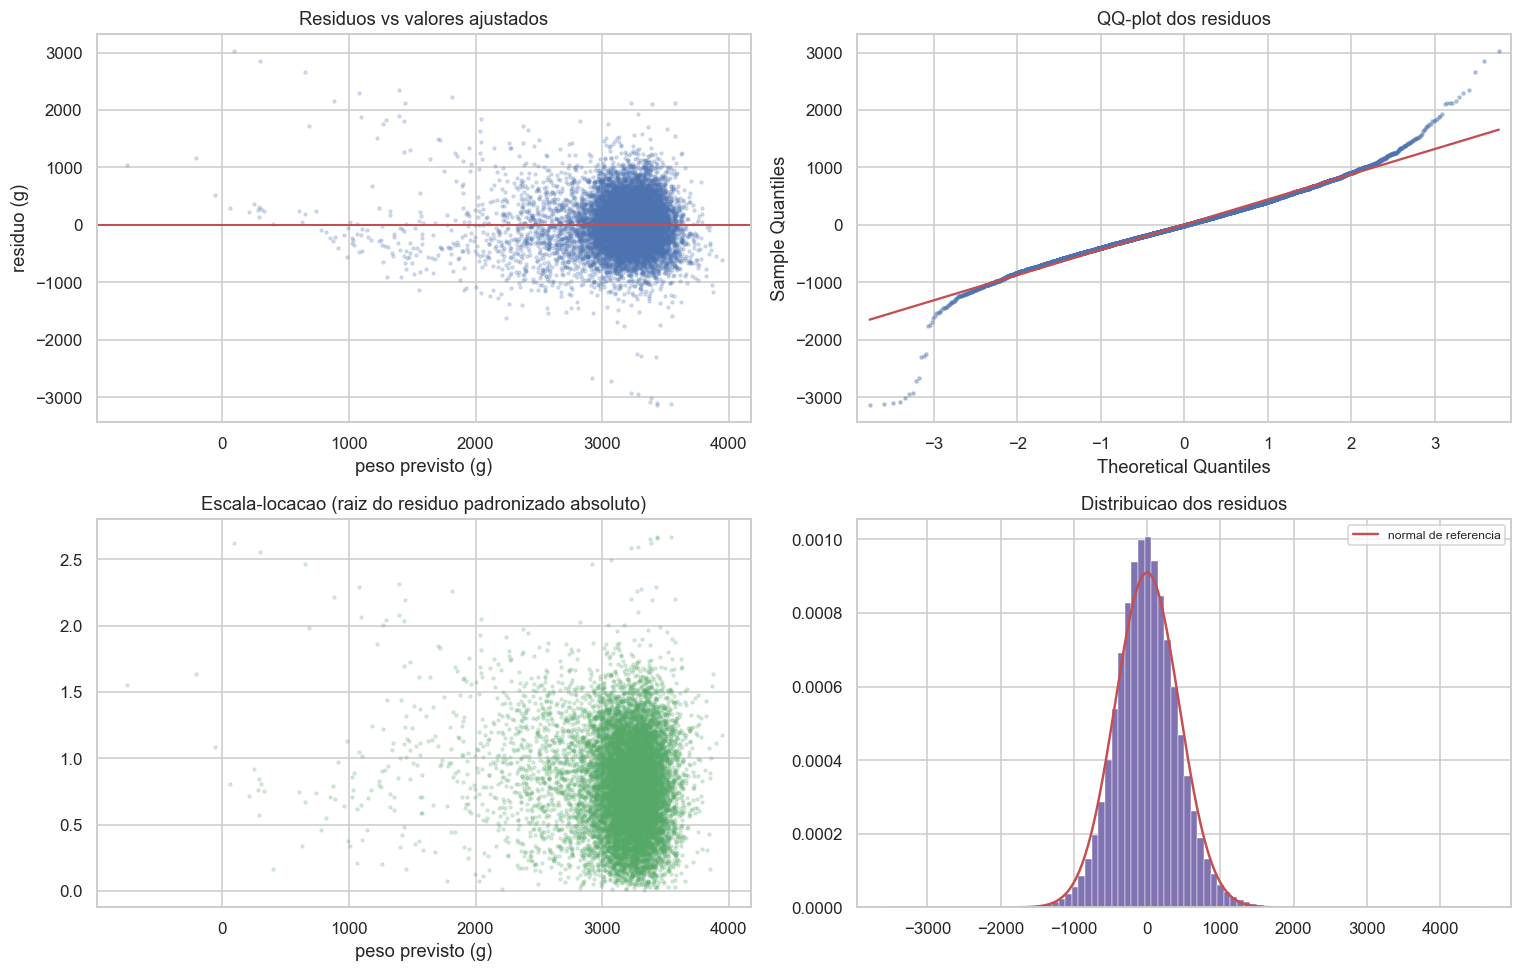

In [37]:
ajustado = m3.fittedvalues
residuo = m3.resid
residuo_padronizado = residuo / np.sqrt(m3.mse_resid)
amostra_diagnostico = rng.choice(len(residuo), size=12000, replace=False)

figura, eixos = plt.subplots(2, 2, figsize=(14, 9))

eixos[0, 0].scatter(ajustado.iloc[amostra_diagnostico], residuo.iloc[amostra_diagnostico],
                    s=4, alpha=0.2, color="#4C72B0")
eixos[0, 0].axhline(0, color="#C44E52", linewidth=1.3)
eixos[0, 0].set_title("Residuos vs valores ajustados")
eixos[0, 0].set_xlabel("peso previsto (g)")
eixos[0, 0].set_ylabel("residuo (g)")

sm.qqplot(residuo.iloc[amostra_diagnostico], line="s", ax=eixos[0, 1], markersize=2, alpha=0.35)
eixos[0, 1].set_title("QQ-plot dos residuos")

eixos[1, 0].scatter(ajustado.iloc[amostra_diagnostico],
                    np.sqrt(np.abs(residuo_padronizado.iloc[amostra_diagnostico])),
                    s=4, alpha=0.2, color="#55A868")
eixos[1, 0].set_title("Escala-locacao (raiz do residuo padronizado absoluto)")
eixos[1, 0].set_xlabel("peso previsto (g)")

eixos[1, 1].hist(residuo, bins=90, color="#8172B2", edgecolor="white", linewidth=0.3, density=True)
grade = np.linspace(residuo.min(), residuo.max(), 400)
eixos[1, 1].plot(grade, st.norm.pdf(grade, residuo.mean(), residuo.std(ddof=1)),
                 color="#C44E52", linewidth=1.6, label="normal de referencia")
eixos[1, 1].set_title("Distribuicao dos residuos")
eixos[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [38]:
lm_bp, p_bp, f_bp, p_f_bp = het_breuschpagan(residuo, m3.model.exog)
durbin_watson = sm.stats.durbin_watson(residuo)
amostra_jarque = residuo.sample(5000, random_state=SEED)
jb_estatistica, jb_p = st.jarque_bera(amostra_jarque)
shapiro_estatistica, shapiro_p = st.shapiro(residuo.sample(4000, random_state=SEED))

pd.Series({
    "media_dos_residuos": residuo.mean(),
    "desvio_dos_residuos": residuo.std(ddof=1),
    "assimetria": st.skew(residuo),
    "curtose_excesso": st.kurtosis(residuo),
    "breusch_pagan_LM": lm_bp,
    "breusch_pagan_gl": int(m3.df_model),
    "breusch_pagan_p": p_bp,
    "durbin_watson": durbin_watson,
    "jarque_bera_estatistica": jb_estatistica,
    "jarque_bera_p": jb_p,
    "shapiro_estatistica": shapiro_estatistica,
    "shapiro_p": shapiro_p,
    "condition_number": m3.condition_number,
}).round(6).to_frame("diagnostico de M3")

,diagnostico de M3
media_dos_residuos,-0.000
desvio_dos_residuos,438.525
assimetria,0.017
curtose_excesso,2.753
breusch_pagan_LM,"49,243.131"
breusch_pagan_gl,20.000
breusch_pagan_p,0.000
durbin_watson,1.995
jarque_bera_estatistica,"1,833.542"
jarque_bera_p,0.000


In [39]:
m3_robusto = m3.get_robustcov_results(cov_type="HC3")

comparacao_erros = pd.DataFrame({
    "coeficiente": m3.params,
    "erro_padrao_MQO": m3.bse,
    "erro_padrao_HC3": m3_robusto.bse,
    "t_MQO": m3.tvalues,
    "t_HC3": m3_robusto.tvalues,
    "p_MQO": m3.pvalues,
    "p_HC3": m3_robusto.pvalues,
}, index=m3.params.index)
comparacao_erros["razao_HC3_MQO"] = (
    comparacao_erros["erro_padrao_HC3"] / comparacao_erros["erro_padrao_MQO"]
)
display(comparacao_erros.round(5))

print("coeficientes que mudam de decisao ao nivel de 5% com erros robustos:")
mudanca = comparacao_erros.loc[
    (comparacao_erros["p_MQO"] < ALPHA) != (comparacao_erros["p_HC3"] < ALPHA)
]
print(mudanca.index.tolist() if len(mudanca) else "nenhum")

,coeficiente,erro_padrao_MQO,erro_padrao_HC3,t_MQO,t_HC3,p_MQO,p_HC3,razao_HC3_MQO
Intercept,"2,998.112",2.966,3.071,"1,010.758",976.223,0.000,0.000,1.035
"C(REGIAO, Treatment('SE'))[T.CO]",3.347,1.538,1.500,2.176,2.232,0.030,0.026,0.975
"C(REGIAO, Treatment('SE'))[T.N]",52.400,1.519,1.589,34.504,32.973,0.000,0.000,1.046
"C(REGIAO, Treatment('SE'))[T.NE]",47.047,1.108,1.124,42.452,41.847,0.000,0.000,1.014
"C(REGIAO, Treatment('SE'))[T.S]",22.833,1.283,1.229,17.796,18.584,0.000,0.000,0.958
"C(RACA_MAE, Treatment('Branca'))[T.Amarela]",-15.715,6.340,6.093,-2.479,-2.579,0.013,0.010,0.961
"C(RACA_MAE, Treatment('Branca'))[T.Indigena]",-15.996,3.920,4.308,-4.080,-3.714,0.000,0.000,1.099
"C(RACA_MAE, Treatment('Branca'))[T.Parda]",-5.769,1.029,1.009,-5.605,-5.715,0.000,0.000,0.981
"C(RACA_MAE, Treatment('Branca'))[T.Preta]",-27.048,1.652,1.659,-16.377,-16.307,0.000,0.000,1.004
SEMAGESTAC_C,115.375,0.300,0.385,384.259,299.792,0.000,0.000,1.282


coeficientes que mudam de decisao ao nivel de 5% com erros robustos:
nenhum


In [40]:
limite_inferior, limite_superior = np.percentile(residuo, [1, 99])
sem_extremos = treino.loc[(residuo > limite_inferior) & (residuo < limite_superior)]
m3_sem_extremos = smf.ols(FORMULA_M3, data=sem_extremos).fit()

sensibilidade = pd.DataFrame({
    "M3_completo": m3.params,
    "M3_sem_1%_extremos": m3_sem_extremos.params,
})
sensibilidade["variacao_%"] = (
    (sensibilidade["M3_sem_1%_extremos"] / sensibilidade["M3_completo"] - 1) * 100
)
display(sensibilidade.round(3))
print(f"observacoes removidas: {len(treino) - len(sem_extremos):,}")
print(f"R2 sem extremos: {m3_sem_extremos.rsquared:.4f} (completo: {m3.rsquared:.4f})")

,M3_completo,M3_sem_1%_extremos,variacao_%
Intercept,"2,998.112","3,019.019",0.697
"C(REGIAO, Treatment('SE'))[T.CO]",3.347,4.772,42.562
"C(REGIAO, Treatment('SE'))[T.N]",52.400,48.887,-6.704
"C(REGIAO, Treatment('SE'))[T.NE]",47.047,46.523,-1.114
"C(REGIAO, Treatment('SE'))[T.S]",22.833,23.207,1.637
"C(RACA_MAE, Treatment('Branca'))[T.Amarela]",-15.715,-16.883,7.430
"C(RACA_MAE, Treatment('Branca'))[T.Indigena]",-15.996,-16.145,0.931
"C(RACA_MAE, Treatment('Branca'))[T.Parda]",-5.769,-5.706,-1.089
"C(RACA_MAE, Treatment('Branca'))[T.Preta]",-27.048,-26.460,-2.176
SEMAGESTAC_C,115.375,115.920,0.472


observacoes removidas: 22,220
R2 sem extremos: 0.4259 (completo: 0.3581)


In [41]:
previsto = m3.predict(teste)
observado = teste["PESO"]
erro = observado - previsto

metricas_teste = pd.Series({
    "n_teste": len(teste),
    "R2_treino": m3.rsquared,
    "R2_teste": r2_score(observado, previsto),
    "RMSE_teste": np.sqrt(mean_squared_error(observado, previsto)),
    "MAE_teste": mean_absolute_error(observado, previsto),
    "erro_medio": erro.mean(),
    "erro_mediano": erro.median(),
    "desvio_padrao_do_erro": erro.std(ddof=1),
    "erro_absoluto_p90": erro.abs().quantile(0.90),
    "MAPE_%": (erro.abs() / observado).mean() * 100,
    "desvio_padrao_do_desfecho": observado.std(ddof=1),
})
display(metricas_teste.round(4).to_frame("desempenho de M3 fora da amostra"))

print(f"reducao do erro em relacao a media ingenua: "
      f"{(1 - metricas_teste['RMSE_teste'] / metricas_teste['desvio_padrao_do_desfecho']) * 100:.1f}%")

,desempenho de M3 fora da amostra
n_teste,"277,735.000"
R2_treino,0.358
R2_teste,0.368
RMSE_teste,437.128
MAE_teste,333.446
erro_medio,-0.159
erro_mediano,-9.235
desvio_padrao_do_erro,437.129
erro_absoluto_p90,692.117
MAPE_%,11.987


reducao do erro em relacao a media ingenua: 20.5%


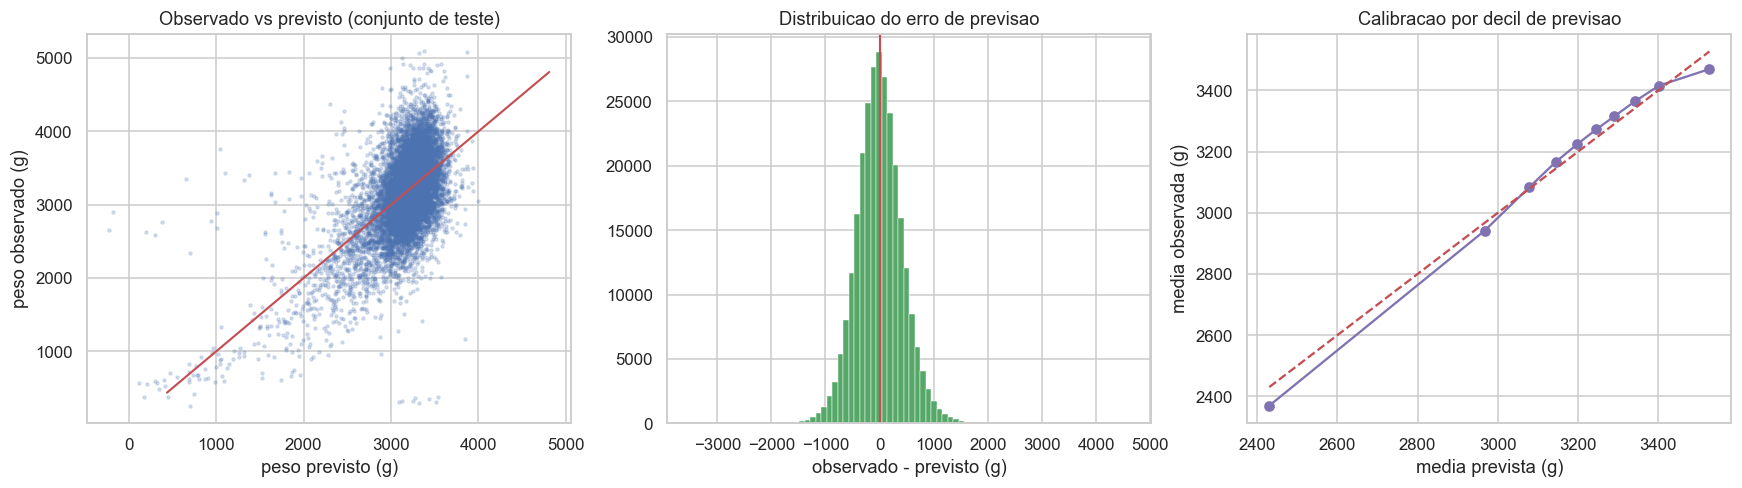

,observado,previsto
decil,,
0,"2,369.500","2,430.200"
1,"2,941.500","2,967.000"
2,"3,083.600","3,078.400"
3,"3,165.900","3,144.000"
4,"3,223.900","3,197.500"
5,"3,272.500","3,245.300"
6,"3,315.200","3,290.200"
7,"3,363.800","3,341.200"
8,"3,415.600","3,401.600"


In [42]:
amostra_previsao = rng.choice(len(teste), size=12000, replace=False)

figura, eixos = plt.subplots(1, 3, figsize=(16, 4.6))

eixos[0].scatter(previsto.iloc[amostra_previsao], observado.iloc[amostra_previsao],
                 s=4, alpha=0.2, color="#4C72B0")
limites = [observado.quantile(0.001), observado.quantile(0.999)]
eixos[0].plot(limites, limites, color="#C44E52", linewidth=1.4)
eixos[0].set_title("Observado vs previsto (conjunto de teste)")
eixos[0].set_xlabel("peso previsto (g)")
eixos[0].set_ylabel("peso observado (g)")

eixos[1].hist(erro, bins=80, color="#55A868", edgecolor="white", linewidth=0.3)
eixos[1].axvline(0, color="#C44E52", linewidth=1.4)
eixos[1].set_title("Distribuicao do erro de previsao")
eixos[1].set_xlabel("observado - previsto (g)")

decis = pd.qcut(previsto, 10, labels=False)
calibracao = pd.DataFrame({"decil": decis, "observado": observado, "previsto": previsto}).groupby("decil").mean()
eixos[2].plot(calibracao["previsto"], calibracao["observado"], marker="o", color="#8172B2")
eixos[2].plot(calibracao["previsto"], calibracao["previsto"], linestyle="--", color="#C44E52")
eixos[2].set_title("Calibracao por decil de previsao")
eixos[2].set_xlabel("media prevista (g)")
eixos[2].set_ylabel("media observada (g)")

plt.tight_layout()
plt.show()

calibracao.round(1)

In [43]:
CENARIOS = pd.DataFrame([
    {"rotulo": "Referencia: termo, pre-natal adequado",
     "SEMAGESTAC_C": 0.0, "CONSPRENAT": 9.0, "MESPRENAT": 2.0, "IDADEMAE_C": 0.0,
     "ANOS_ESTUDO": 10.0, "QTDFILVIVO": 1.0, "SEXO_M": 1.0, "CESAREA": 0.0,
     "MULTIPLA": 0.0, "ANOMALIA": 0.0, "SEM_COMPANHEIRO": 0.0, "REGIAO": "SE", "RACA_MAE": "Branca"},
    {"rotulo": "Termo, pre-natal insuficiente e tardio",
     "SEMAGESTAC_C": 0.0, "CONSPRENAT": 3.0, "MESPRENAT": 6.0, "IDADEMAE_C": 0.0,
     "ANOS_ESTUDO": 10.0, "QTDFILVIVO": 1.0, "SEXO_M": 1.0, "CESAREA": 0.0,
     "MULTIPLA": 0.0, "ANOMALIA": 0.0, "SEM_COMPANHEIRO": 0.0, "REGIAO": "SE", "RACA_MAE": "Branca"},
    {"rotulo": "Prematuro de 34 semanas",
     "SEMAGESTAC_C": -5.0, "CONSPRENAT": 6.0, "MESPRENAT": 3.0, "IDADEMAE_C": 0.0,
     "ANOS_ESTUDO": 10.0, "QTDFILVIVO": 1.0, "SEXO_M": 1.0, "CESAREA": 0.0,
     "MULTIPLA": 0.0, "ANOMALIA": 0.0, "SEM_COMPANHEIRO": 0.0, "REGIAO": "SE", "RACA_MAE": "Branca"},
    {"rotulo": "Gemelar de 36 semanas",
     "SEMAGESTAC_C": -3.0, "CONSPRENAT": 8.0, "MESPRENAT": 2.0, "IDADEMAE_C": 2.0,
     "ANOS_ESTUDO": 10.0, "QTDFILVIVO": 0.0, "SEXO_M": 0.0, "CESAREA": 1.0,
     "MULTIPLA": 1.0, "ANOMALIA": 0.0, "SEM_COMPANHEIRO": 0.0, "REGIAO": "SE", "RACA_MAE": "Branca"},
    {"rotulo": "Mae adolescente, baixa escolaridade, pre-natal tardio",
     "SEMAGESTAC_C": -1.0, "CONSPRENAT": 4.0, "MESPRENAT": 5.0, "IDADEMAE_C": -11.0,
     "ANOS_ESTUDO": 5.5, "QTDFILVIVO": 0.0, "SEXO_M": 0.0, "CESAREA": 0.0,
     "MULTIPLA": 0.0, "ANOMALIA": 0.0, "SEM_COMPANHEIRO": 1.0, "REGIAO": "NE", "RACA_MAE": "Parda"},
]).set_index("rotulo")

CENARIOS["SEMAGESTAC_C2"] = CENARIOS["SEMAGESTAC_C"] ** 2

predicao_cenarios = m3.get_prediction(CENARIOS).summary_frame(alpha=ALPHA)
predicao_cenarios.index = CENARIOS.index
predicao_cenarios = predicao_cenarios.rename(columns={
    "mean": "peso_previsto", "mean_se": "erro_padrao",
    "mean_ci_lower": "ic_media_inf", "mean_ci_upper": "ic_media_sup",
    "obs_ci_lower": "ic_predicao_inf", "obs_ci_upper": "ic_predicao_sup",
})
predicao_cenarios["amplitude_ic_media"] = (
    predicao_cenarios["ic_media_sup"] - predicao_cenarios["ic_media_inf"]
)
predicao_cenarios["amplitude_ic_predicao"] = (
    predicao_cenarios["ic_predicao_sup"] - predicao_cenarios["ic_predicao_inf"]
)
predicao_cenarios.round(1)

,peso_previsto,erro_padrao,ic_media_inf,ic_media_sup,ic_predicao_inf,ic_predicao_sup,amplitude_ic_media,amplitude_ic_predicao
rotulo,,,,,,,,
"Referencia: termo, pre-natal adequado","3,293.300",1.200,"3,290.900","3,295.800","2,433.800","4,152.800",4.900,"1,719.000"
"Termo, pre-natal insuficiente e tardio","3,235.300",1.800,"3,231.700","3,238.800","2,375.700","4,094.800",7.100,"1,719.000"
Prematuro de 34 semanas,"2,611.700",1.600,"2,608.600","2,614.800","1,752.200","3,471.200",6.100,"1,719.000"
Gemelar de 36 semanas,"2,321.700",3.000,"2,315.900","2,327.500","1,462.200","3,181.200",11.700,"1,719.000"
"Mae adolescente, baixa escolaridade, pre-natal tardio","2,960.600",1.600,"2,957.400","2,963.700","2,101.000","3,820.100",6.300,"1,719.000"


In [44]:
cobertura = m3.get_prediction(teste.sample(50000, random_state=SEED))
quadro_cobertura = cobertura.summary_frame(alpha=ALPHA)
amostra_cobertura = teste.sample(50000, random_state=SEED)["PESO"].values

dentro_predicao = (
    (amostra_cobertura >= quadro_cobertura["obs_ci_lower"].values)
    & (amostra_cobertura <= quadro_cobertura["obs_ci_upper"].values)
).mean()

print(f"cobertura empirica do intervalo de predicao de 95%: {dentro_predicao * 100:.2f}%")
print(f"amplitude media do intervalo de predicao: "
      f"{(quadro_cobertura['obs_ci_upper'] - quadro_cobertura['obs_ci_lower']).mean():,.0f} g")
print(f"amplitude media do IC da media: "
      f"{(quadro_cobertura['mean_ci_upper'] - quadro_cobertura['mean_ci_lower']).mean():,.0f} g")

cobertura empirica do intervalo de predicao de 95%: 95.24%
amplitude media do intervalo de predicao: 1,719 g
amplitude media do IC da media: 7 g


In [45]:
CONSULTAS_MINIMAS = 6
MES_IDEAL = 3

contrafactual = teste.copy()
elegiveis = (
    (contrafactual["CONSPRENAT"] < CONSULTAS_MINIMAS) | (contrafactual["MESPRENAT"] > MES_IDEAL)
)
contrafactual.loc[elegiveis, "CONSPRENAT"] = np.maximum(
    contrafactual.loc[elegiveis, "CONSPRENAT"], CONSULTAS_MINIMAS
)
contrafactual.loc[elegiveis, "MESPRENAT"] = np.minimum(
    contrafactual.loc[elegiveis, "MESPRENAT"], MES_IDEAL
)

previsto_atual = m3.predict(teste)
previsto_contrafactual = m3.predict(contrafactual)
ganho_individual = previsto_contrafactual - previsto_atual

resultado_simulacao = pd.Series({
    "n_teste": len(teste),
    "gestacoes_elegiveis": int(elegiveis.sum()),
    "proporcao_elegivel_%": elegiveis.mean() * 100,
    "peso_medio_previsto_atual": previsto_atual.mean(),
    "peso_medio_previsto_contrafactual": previsto_contrafactual.mean(),
    "ganho_medio_populacional_g": ganho_individual.mean(),
    "ganho_medio_entre_elegiveis_g": ganho_individual[elegiveis].mean(),
    "ganho_maximo_g": ganho_individual.max(),
})
display(resultado_simulacao.round(3).to_frame("simulacao contrafactual"))

ic_consultas = m3.conf_int().loc["CONSPRENAT"]
ic_mes = m3.conf_int().loc["MESPRENAT"]
consultas_faltantes = (CONSULTAS_MINIMAS - teste.loc[elegiveis, "CONSPRENAT"]).clip(lower=0)
meses_antecipados = (teste.loc[elegiveis, "MESPRENAT"] - MES_IDEAL).clip(lower=0)

ganho_inferior = (consultas_faltantes * ic_consultas[0] - meses_antecipados * ic_mes[1]).mean()
ganho_superior = (consultas_faltantes * ic_consultas[1] - meses_antecipados * ic_mes[0]).mean()

print(f"ganho entre elegiveis com IC95% dos coeficientes: "
      f"{ganho_individual[elegiveis].mean():.1f} g "
      f"({ganho_inferior:.1f} g; {ganho_superior:.1f} g)")

,simulacao contrafactual
n_teste,"277,735.000"
gestacoes_elegiveis,"52,550.000"
proporcao_elegivel_%,18.921
peso_medio_previsto_atual,"3,162.258"
peso_medio_previsto_contrafactual,"3,164.843"
ganho_medio_populacional_g,2.585
ganho_medio_entre_elegiveis_g,13.660
ganho_maximo_g,62.092


ganho entre elegiveis com IC95% dos coeficientes: 13.7 g (12.4 g; 14.9 g)


In [46]:
LIMIAR_BPN = 2500
sigma_residual = np.sqrt(m3.mse_resid)

probabilidade_atual = st.norm.cdf((LIMIAR_BPN - previsto_atual) / sigma_residual)
probabilidade_contrafactual = st.norm.cdf((LIMIAR_BPN - previsto_contrafactual) / sigma_residual)

prevalencia_observada = teste["BAIXO_PESO"].mean()
prevalencia_estimada = probabilidade_atual.mean()
prevalencia_contrafactual = probabilidade_contrafactual.mean()
reducao = prevalencia_estimada - prevalencia_contrafactual

nascimentos_periodo = len(completo)
nascimentos_ano = nascimentos_periodo / 8 * 12

display(pd.Series({
    "sigma_residual_g": sigma_residual,
    "prevalencia_observada_%": prevalencia_observada * 100,
    "prevalencia_estimada_pelo_modelo_%": prevalencia_estimada * 100,
    "erro_de_calibracao_pp": (prevalencia_estimada - prevalencia_observada) * 100,
    "prevalencia_contrafactual_%": prevalencia_contrafactual * 100,
    "reducao_pp": reducao * 100,
    "reducao_relativa_%": reducao / prevalencia_estimada * 100,
    "casos_evitados_no_periodo": reducao * nascimentos_periodo,
    "casos_evitados_projetados_ano": reducao * nascimentos_ano,
}).round(3).to_frame("impacto estimado da adequacao do pre-natal"))

estimativa_bivariada = diferenca_risco * n_inadequado
estimativa_ajustada = reducao * nascimentos_periodo

pd.Series({
    "estimativa_bivariada_H5": estimativa_bivariada,
    "estimativa_ajustada_M3": estimativa_ajustada,
    "razao_entre_estimativas": estimativa_bivariada / estimativa_ajustada,
    "fracao_atribuivel_a_confundimento_%": (1 - estimativa_ajustada / estimativa_bivariada) * 100,
}).round(2).to_frame("comparacao das duas estimativas de impacto")

,impacto estimado da adequacao do pre-natal
sigma_residual_g,438.529
prevalencia_observada_%,9.108
prevalencia_estimada_pelo_modelo_%,9.981
erro_de_calibracao_pp,0.873
prevalencia_contrafactual_%,9.893
reducao_pp,0.088
reducao_relativa_%,0.880
casos_evitados_no_periodo,"1,219.789"
casos_evitados_projetados_ano,"1,829.683"


,comparacao das duas estimativas de impacto
estimativa_bivariada_H5,"15,511.560"
estimativa_ajustada_M3,"1,219.790"
razao_entre_estimativas,12.720
fracao_atribuivel_a_confundimento_%,92.140


In [47]:
agregado_uf = (
    completo.groupby("UF")
    .agg(nascimentos=("PESO", "size"), peso_medio=("PESO", "mean"),
         taxa_bpn=("BAIXO_PESO", "mean"), cobertura_prenatal=("PRENATAL_ADEQ", "mean"),
         escolaridade_media=("ANOS_ESTUDO", "mean"), taxa_cesarea=("CESAREA", "mean"),
         taxa_prematuro=("PREMATURO", "mean"), consultas_media=("CONSPRENAT", "mean"))
    .dropna()
)
for coluna_taxa in ["taxa_bpn", "cobertura_prenatal", "taxa_cesarea", "taxa_prematuro"]:
    agregado_uf[coluna_taxa] *= 100

modelo_agregado = smf.ols(
    "taxa_bpn ~ cobertura_prenatal + escolaridade_media + taxa_cesarea", data=agregado_uf
).fit()
print(modelo_agregado.summary())

                            OLS Regression Results                            
Dep. Variable:               taxa_bpn   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     3.357
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0363
Time:                        16:14:12   Log-Likelihood:                -32.452
No. Observations:                  27   AIC:                             72.90
Df Residuals:                      23   BIC:                             78.09
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.2320      2

In [48]:
display(pd.DataFrame({
    "coeficiente": modelo_agregado.params,
    "erro_padrao": modelo_agregado.bse,
    "valor_p": modelo_agregado.pvalues,
    "ic_inferior": modelo_agregado.conf_int()[0],
    "ic_superior": modelo_agregado.conf_int()[1],
}).round(4))

print(f"n de unidades: {len(agregado_uf)} | gl dos residuos: {int(modelo_agregado.df_resid)}")
print(f"R2: {modelo_agregado.rsquared:.3f} | R2 ajustado: {modelo_agregado.rsquared_adj:.3f}")

agregado_uf["bpn_previsto"] = modelo_agregado.fittedvalues
agregado_uf["residuo"] = modelo_agregado.resid
display(agregado_uf.sort_values("residuo", ascending=False)
        [["nascimentos", "taxa_bpn", "bpn_previsto", "residuo", "cobertura_prenatal",
          "taxa_cesarea", "escolaridade_media"]].round(2))

,coeficiente,erro_padrao,valor_p,ic_inferior,ic_superior
Intercept,1.232,2.751,0.658,-4.459,6.923
cobertura_prenatal,0.024,0.041,0.565,-0.061,0.109
escolaridade_media,0.803,0.380,0.046,0.016,1.590
taxa_cesarea,-0.042,0.031,0.191,-0.106,0.022


n de unidades: 27 | gl dos residuos: 23
R2: 0.305 | R2 ajustado: 0.214


,nascimentos,taxa_bpn,bpn_previsto,residuo,cobertura_prenatal,taxa_cesarea,escolaridade_media
UF,,,,,,,
GO,53538,9.850,8.850,1.000,80.940,70.020,10.720
BA,84091,9.430,8.520,0.910,76.910,57.270,9.760
RJ,88794,9.600,8.790,0.810,81.060,63.580,10.310
RN,21291,8.840,8.050,0.790,82.130,72.690,9.830
RS,69556,9.510,8.830,0.680,83.800,67.040,10.450
PA,67069,8.350,7.730,0.620,69.150,63.290,9.320
CE,46448,8.760,8.150,0.610,83.730,71.840,9.860
DF,19481,10.360,9.820,0.550,77.800,58.470,11.410
PI,22142,8.830,8.290,0.540,79.040,68.300,9.980


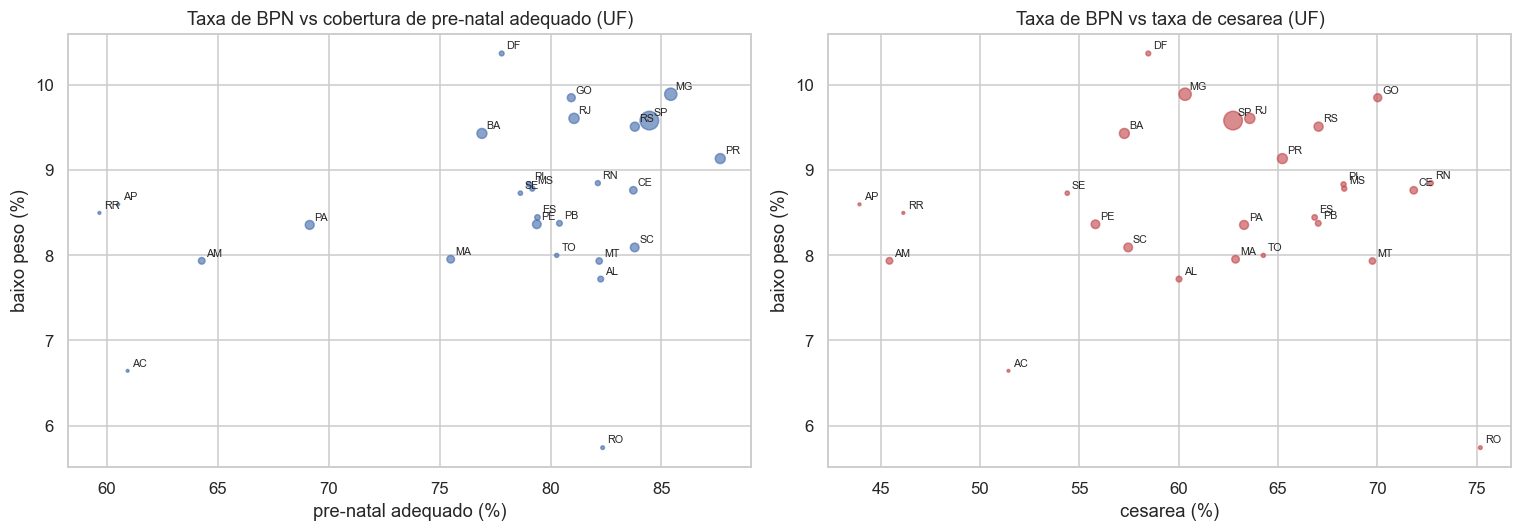

In [49]:
figura, eixos = plt.subplots(1, 2, figsize=(14, 5))

eixos[0].scatter(agregado_uf["cobertura_prenatal"], agregado_uf["taxa_bpn"],
                 s=agregado_uf["nascimentos"] / 2000, alpha=0.65, color="#4C72B0")
for uf, linha in agregado_uf.iterrows():
    eixos[0].annotate(uf, (linha["cobertura_prenatal"], linha["taxa_bpn"]), fontsize=7,
                      xytext=(3, 3), textcoords="offset points")
eixos[0].set_title("Taxa de BPN vs cobertura de pre-natal adequado (UF)")
eixos[0].set_xlabel("pre-natal adequado (%)")
eixos[0].set_ylabel("baixo peso (%)")

eixos[1].scatter(agregado_uf["taxa_cesarea"], agregado_uf["taxa_bpn"],
                 s=agregado_uf["nascimentos"] / 2000, alpha=0.65, color="#C44E52")
for uf, linha in agregado_uf.iterrows():
    eixos[1].annotate(uf, (linha["taxa_cesarea"], linha["taxa_bpn"]), fontsize=7,
                      xytext=(3, 3), textcoords="offset points")
eixos[1].set_title("Taxa de BPN vs taxa de cesarea (UF)")
eixos[1].set_xlabel("cesarea (%)")
eixos[1].set_ylabel("baixo peso (%)")

plt.tight_layout()
plt.show()

In [50]:
DESTINO = Path("dados")
DESTINO.mkdir(exist_ok=True)

COLUNAS_EXPORTACAO = [
    "UF", "REGIAO", "MES_NASC", "PESO", "SEMAGESTAC", "IDADEMAE", "CONSPRENAT", "MESPRENAT",
    "ANOS_ESTUDO", "ESC_CAT", "RACA_MAE", "FAIXA_MAE", "QTDFILVIVO", "QTDFILMORT",
    "SEXO_M", "CESAREA", "MULTIPLA", "ANOMALIA", "SEM_COMPANHEIRO", "PRENATAL_ADEQ",
    "BAIXO_PESO", "MUITO_BAIXO_PESO", "PREMATURO", "APGAR5", "APGAR5_BAIXO", "HOSPITALAR",
]

fracao = min(1.0, 150_000 / len(completo))
indices_amostra = completo.groupby("UF").sample(frac=fracao, random_state=SEED).index
amostra_dashboard = completo.loc[indices_amostra, COLUNAS_EXPORTACAO].reset_index(drop=True)
amostra_dashboard.to_parquet(DESTINO / "sinasc_amostra.parquet", index=False)

agregado_uf.to_parquet(DESTINO / "agregado_uf.parquet")
serie_mensal.rename_axis("mes").reset_index().assign(
    mes=lambda frame: frame["mes"].astype(str)
).to_parquet(DESTINO / "serie_mensal.parquet", index=False)
por_semana.rename_axis("semana").reset_index().to_parquet(DESTINO / "agregado_semana.parquet", index=False)
resumo_escolaridade.rename_axis("escolaridade").reset_index().to_parquet(
    DESTINO / "agregado_escolaridade.parquet", index=False
)
resumo_regiao.rename_axis("regiao").reset_index().to_parquet(
    DESTINO / "agregado_regiao.parquet", index=False
)

coeficientes_exportacao = pd.DataFrame({
    "termo": m3.params.index,
    "coeficiente": m3.params.values,
    "erro_padrao_hc3": m3_robusto.bse,
    "t_hc3": m3_robusto.tvalues,
    "valor_p_hc3": m3_robusto.pvalues,
    "ic_inferior": m3.conf_int()[0].values,
    "ic_superior": m3.conf_int()[1].values,
})
coeficientes_exportacao.to_parquet(DESTINO / "coeficientes_m3.parquet", index=False)
comparacao_modelos.reset_index().to_parquet(DESTINO / "comparacao_modelos.parquet", index=False)
prevalencias.reset_index().to_parquet(DESTINO / "prevalencias.parquet", index=False)

testes_exportacao = pd.DataFrame([
    {"hipotese": "H1 pre-natal adequado vs inadequado", "teste": "t de Welch",
     "estatistica": h1["t_observado"], "graus_liberdade": h1["graus_liberdade_welch"],
     "valor_p": h1["valor_p"], "efeito": h1["diferenca"],
     "ic_inferior": h1["ic_inferior"], "ic_superior": h1["ic_superior"],
     "medida_efeito": "d de Cohen", "valor_efeito": h1["d_de_cohen"]},
    {"hipotese": "H2 cesareo vs vaginal", "teste": "t de Welch",
     "estatistica": h2["t_observado"], "graus_liberdade": h2["graus_liberdade_welch"],
     "valor_p": h2["valor_p"], "efeito": h2["diferenca"],
     "ic_inferior": h2["ic_inferior"], "ic_superior": h2["ic_superior"],
     "medida_efeito": "d de Cohen", "valor_efeito": h2["d_de_cohen"]},
    {"hipotese": "H2b adolescente vs 20-34", "teste": "t de Welch",
     "estatistica": h2_adolescente["t_observado"],
     "graus_liberdade": h2_adolescente["graus_liberdade_welch"],
     "valor_p": h2_adolescente["valor_p"], "efeito": h2_adolescente["diferenca"],
     "ic_inferior": h2_adolescente["ic_inferior"], "ic_superior": h2_adolescente["ic_superior"],
     "medida_efeito": "d de Cohen", "valor_efeito": h2_adolescente["d_de_cohen"]},
    {"hipotese": "H3 escolaridade", "teste": "ANOVA de um fator",
     "estatistica": f_observado, "graus_liberdade": k_grupos - 1, "valor_p": p_anova,
     "efeito": np.nan, "ic_inferior": np.nan, "ic_superior": np.nan,
     "medida_efeito": "eta quadrado", "valor_efeito": eta_quadrado},
    {"hipotese": "H4 correlacao SEMAGESTAC x PESO", "teste": "t sobre r de Pearson",
     "estatistica": t_correlacao, "graus_liberdade": n_par - 2, "valor_p": p_pearson,
     "efeito": r_pearson, "ic_inferior": ic_r[0], "ic_superior": ic_r[1],
     "medida_efeito": "r2", "valor_efeito": r_pearson ** 2},
    {"hipotese": "H5 pre-natal x baixo peso", "teste": "qui-quadrado e z de proporcoes",
     "estatistica": chi2_observado, "graus_liberdade": gl_chi2, "valor_p": p_chi2,
     "efeito": diferenca_risco * 100,
     "ic_inferior": (diferenca_risco - z_critico * erro_padrao_risco) * 100,
     "ic_superior": (diferenca_risco + z_critico * erro_padrao_risco) * 100,
     "medida_efeito": "risco relativo", "valor_efeito": risco_relativo},
])
testes_exportacao.to_parquet(DESTINO / "testes_hipoteses.parquet", index=False)

metricas_exportacao = metricas_teste.rename_axis("metrica").reset_index()
metricas_exportacao.columns = ["metrica", "valor"]
metricas_exportacao.to_parquet(DESTINO / "metricas_modelo.parquet", index=False)

for arquivo in sorted(DESTINO.glob("*.parquet")):
    print(f"{arquivo.name:34s} {arquivo.stat().st_size / 1024 ** 2:8.2f} MB")

agregado_escolaridade.parquet          0.01 MB
agregado_regiao.parquet                0.01 MB
agregado_semana.parquet                0.01 MB
agregado_uf.parquet                    0.01 MB
coeficientes_m3.parquet                0.01 MB
comparacao_modelos.parquet             0.01 MB
metricas_modelo.parquet                0.00 MB
prevalencias.parquet                   0.00 MB
serie_mensal.parquet                   0.00 MB
sinasc_amostra.parquet                 1.19 MB
testes_hipoteses.parquet               0.01 MB


In [51]:
print(f"registros brutos..............: {len(bruto):,}")
print(f"registros apos tratamento.....: {len(dados):,}")
print(f"casos completos...............: {len(completo):,}")
print(f"amostra de modelagem..........: {len(modelagem):,}")
print(f"amostra exportada ao dashboard: {len(amostra_dashboard):,}")
print()
print(f"modelo final..................: M3")
print(f"R2 fora da amostra............: {metricas_teste['R2_teste']:.4f}")
print(f"RMSE fora da amostra..........: {metricas_teste['RMSE_teste']:,.1f} g")
print(f"hipoteses testadas............: 6 (todas com H0 rejeitada ao nivel de 5%)")

registros brutos..............: 1,504,579
registros apos tratamento.....: 1,504,579
casos completos...............: 1,388,675
amostra de modelagem..........: 1,388,675
amostra exportada ao dashboard: 149,999

modelo final..................: M3
R2 fora da amostra............: 0.3681
RMSE fora da amostra..........: 437.1 g
hipoteses testadas............: 6 (todas com H0 rejeitada ao nivel de 5%)
